# INSTITUTO / UNIVERSIDAD [Nombre de tu institución]

## Asignatura: Investigación de Operaciones
## Programa Educativo: Ingeniería en Computación
## Actividad Integradora — Implementación de Modelos de IO con Python

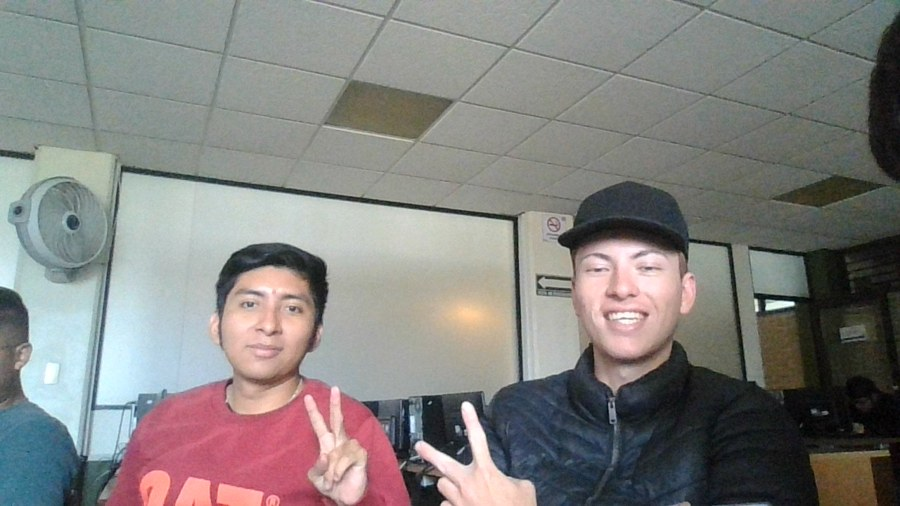

### Integrantes del equipo:
- Akis Aram Seba Toto
- Cristian Saul Soto Vique
- Luis Alberto Rodriguez Rodriguez

### Fecha: 19/11/2026
### Herramientas: Python 3, Jupyter Notebook, NetworkX, Matplotlib, NumPy, Pandas, SciPy

---
**Estructura de cada práctica:** 1) descripción del problema, 2) formulación matemática, 3) importación de bibliotecas,
4) definición de datos, 5) desarrollo del algoritmo, 6) ejecución paso a paso, 7) visualización de resultados
(**una gráfica por cada paso del algoritmo hasta llegar a la solución final**) y 8) análisis final.

# Práctica 1: Árbol de Expansión Mínima (MST)

## 1. Descripción del problema
Una empresa de TI necesita conectar **8 sucursales** (servidores distribuidos) con fibra óptica.
Los costos de instalación entre pares de sucursales se conocen.
Se requiere determinar la red de conexión de **menor costo total** que conecte todas las sucursales
sin ciclos (esto es, un Árbol de Expansión Mínima).

**¿Por qué es un MST?** Cada sucursal es un vértice y cada posible enlace es una arista con peso = costo.
Una red de costo mínimo nunca necesita ciclos: si existiera uno, se podría quitar su arista más cara y seguir
conectados pagando menos. Por eso la solución es un árbol de |V| − 1 = 7 aristas.

## 2. Formulación matemática
Sea G = (V, E) con pesos w(e) ≥ 0.

**Minimizar:**  ∑_{e ∈ T} w(e)

**Sujeto a:**  T ⊆ E es un árbol que conecta todos los vértices de V (|T| = |V| − 1 aristas, sin ciclos).

**Algoritmo elegido: Kruskal.** Es voraz (*greedy*): ordena las aristas de menor a mayor costo y añade cada una
solo si no forma ciclo. Funciona por la *propiedad de corte*: la arista más barata que une dos componentes
distintas siempre pertenece a algún MST.

### 3. Importación de bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 80

### 4. Definición de datos

In [2]:
nodos_mst = ['S1','S2','S3','S4','S5','S6','S7','S8']

aristas_mst = [
    ('S1','S2', 4), ('S1','S3', 8), ('S2','S3', 11),
    ('S2','S4', 8), ('S3','S4', 7), ('S3','S5', 2),
    ('S4','S5', 6), ('S4','S6', 9), ('S5','S6', 4),
    ('S6','S7', 10), ('S6','S8', 3), ('S7','S8', 5),
    ('S5','S8', 12), ('S1','S8', 15)
]

G_mst = nx.Graph()
G_mst.add_weighted_edges_from(aristas_mst)

print(f"Nodos: {G_mst.number_of_nodes()}")
print(f"Aristas: {G_mst.number_of_edges()}")
print(f"Grafo conexo: {nx.is_connected(G_mst)}")
print()
print(pd.DataFrame(aristas_mst, columns=['Origen','Destino','Costo']).to_string(index=False))

Nodos: 8
Aristas: 14
Grafo conexo: True

Origen Destino  Costo
    S1      S2      4
    S1      S3      8
    S2      S3     11
    S2      S4      8
    S3      S4      7
    S3      S5      2
    S4      S5      6
    S4      S6      9
    S5      S6      4
    S6      S7     10
    S6      S8      3
    S7      S8      5
    S5      S8     12
    S1      S8     15


### 5. Desarrollo del algoritmo (Kruskal con Union-Find)

In [3]:
def find(padre, x):
    """Representante del componente de x (con compresión de camino)."""
    while padre[x] != x:
        padre[x] = padre[padre[x]]
        x = padre[x]
    return x

def union(padre, a, b):
    """Une los componentes de a y b. Devuelve False si ya estaban unidos (formaría un ciclo)."""
    ra, rb = find(padre, a), find(padre, b)
    if ra == rb:
        return False
    padre[rb] = ra
    return True

def kruskal_manual(nodos, aristas, verbose=False):
    padre = {n: n for n in nodos}                 # al inicio cada nodo es su propio componente
    mst, costo_total = [], 0
    historial = []                                # guarda cada decisión para graficarla paso a paso
    aristas_ordenadas = sorted(aristas, key=lambda e: e[2])   # criterio voraz: de menor a mayor costo

    if verbose:
        print("Aristas ordenadas por costo:")
        print(aristas_ordenadas)
        print()

    for u, v, w in aristas_ordenadas:
        acepta = union(padre, u, v)
        if acepta:
            mst.append((u, v, w))
            costo_total += w
            if verbose:
                print(f"ACEPTA   {u}-{v} (costo {w})  -> total acumulado = {costo_total}")
        elif verbose:
            print(f"RECHAZA  {u}-{v} (costo {w})  -> formaría un ciclo")
        historial.append({'paso': len(historial) + 1, 'arista': (u, v, w), 'acepta': acepta,
                          'mst': list(mst), 'costo': costo_total})
        if len(mst) == len(nodos) - 1:            # un árbol de 8 nodos tiene 7 aristas
            break
    return mst, costo_total, historial

### 6. Ejecución paso a paso

In [4]:
mst_aristas, costo_mst, historial_k = kruskal_manual(nodos_mst, aristas_mst, verbose=True)

print()
print(f"Aristas del MST ({len(mst_aristas)}): {mst_aristas}")
print(f"Costo total minimo: {costo_mst}")

# Verificación contra la implementación de NetworkX
T_nx = nx.minimum_spanning_tree(G_mst, algorithm='kruskal')
print(f"Costo con NetworkX: {T_nx.size(weight='weight')} | coincide: {T_nx.size(weight='weight') == costo_mst}")
assert T_nx.size(weight='weight') == costo_mst and len(mst_aristas) == len(nodos_mst) - 1

Aristas ordenadas por costo:
[('S3', 'S5', 2), ('S6', 'S8', 3), ('S1', 'S2', 4), ('S5', 'S6', 4), ('S7', 'S8', 5), ('S4', 'S5', 6), ('S3', 'S4', 7), ('S1', 'S3', 8), ('S2', 'S4', 8), ('S4', 'S6', 9), ('S6', 'S7', 10), ('S2', 'S3', 11), ('S5', 'S8', 12), ('S1', 'S8', 15)]

ACEPTA   S3-S5 (costo 2)  -> total acumulado = 2
ACEPTA   S6-S8 (costo 3)  -> total acumulado = 5
ACEPTA   S1-S2 (costo 4)  -> total acumulado = 9
ACEPTA   S5-S6 (costo 4)  -> total acumulado = 13
ACEPTA   S7-S8 (costo 5)  -> total acumulado = 18
ACEPTA   S4-S5 (costo 6)  -> total acumulado = 24
RECHAZA  S3-S4 (costo 7)  -> formaría un ciclo
ACEPTA   S1-S3 (costo 8)  -> total acumulado = 32

Aristas del MST (7): [('S3', 'S5', 2), ('S6', 'S8', 3), ('S1', 'S2', 4), ('S5', 'S6', 4), ('S7', 'S8', 5), ('S4', 'S5', 6), ('S1', 'S3', 8)]
Costo total minimo: 32
Costo con NetworkX: 32.0 | coincide: True


### 7. Visualización de resultados — gráfica paso a paso
Se dibuja **una figura por cada decisión de Kruskal**: aristas aceptadas en rojo, la arista evaluada en
verde (si se acepta) o naranja punteada (si se rechaza por formar ciclo). La última figura es el MST final.

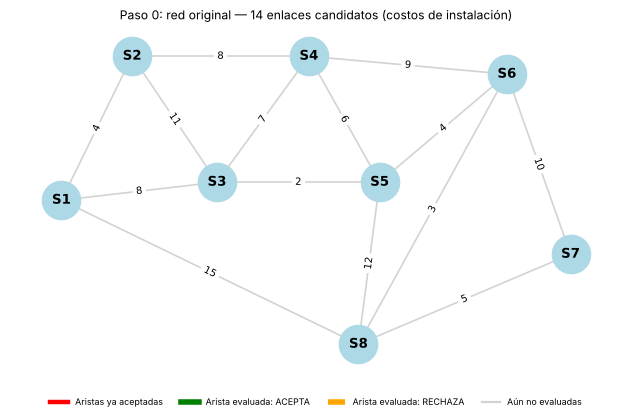

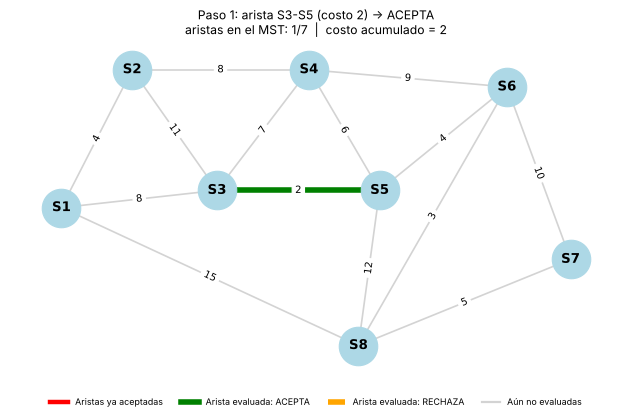

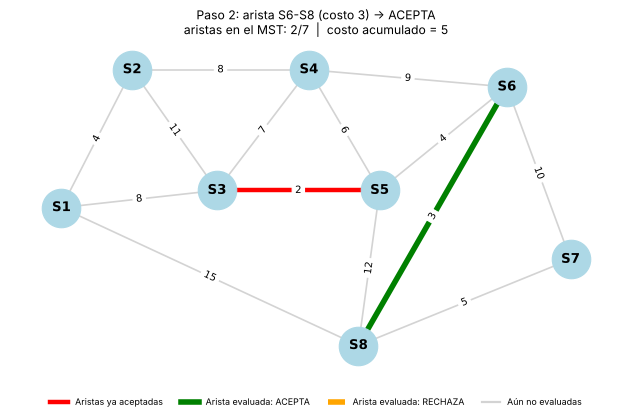

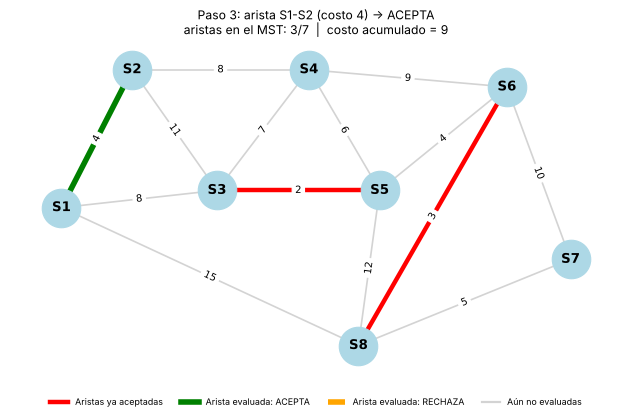

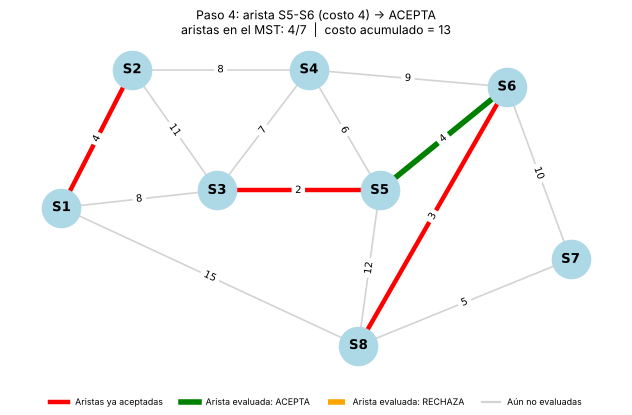

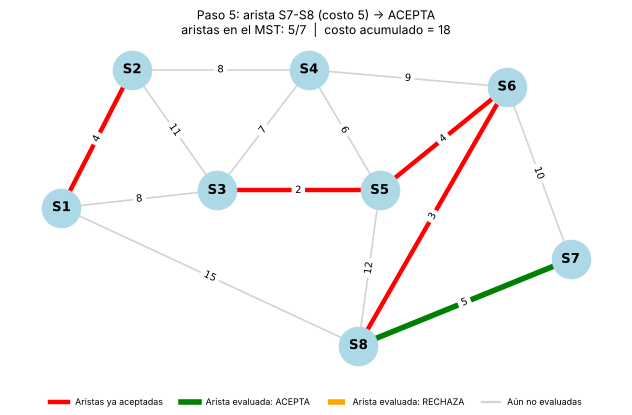

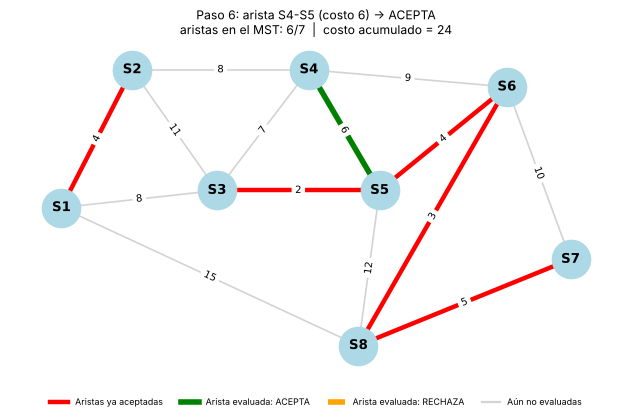

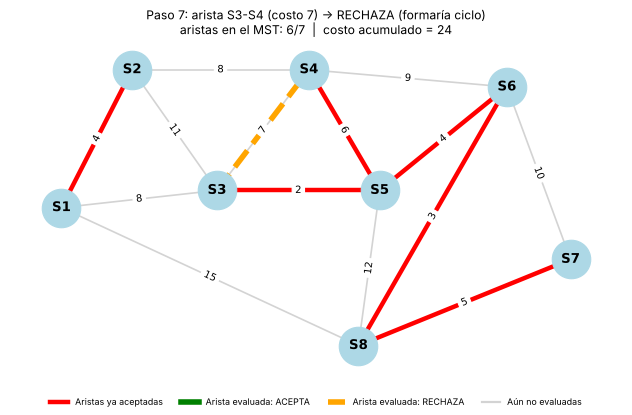

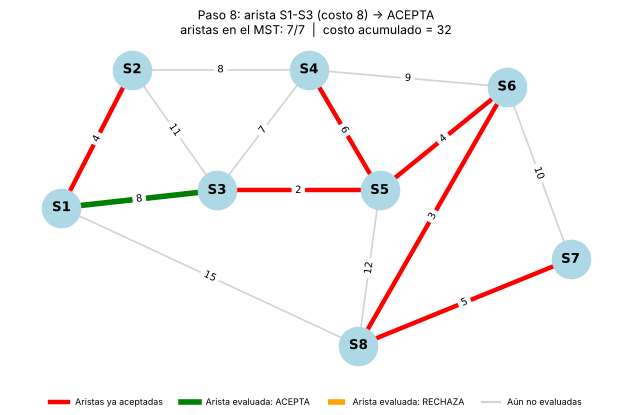

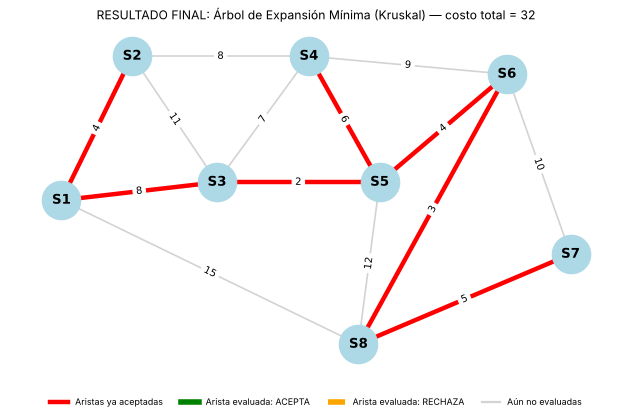

In [5]:
# Posiciones fijas (layout manual) para que todas las figuras sean comparables entre sí
pos_m = {'S1': (0, 1.6), 'S2': (1, 3.2), 'S3': (2.2, 1.8), 'S4': (3.5, 3.2),
         'S5': (4.5, 1.8), 'S6': (6.3, 3), 'S7': (7.2, 1), 'S8': (4.2, 0)}
lbl_m = nx.get_edge_attributes(G_mst, 'weight')

from matplotlib.lines import Line2D
leyenda_k = [Line2D([0], [0], color='red', lw=4, label='Aristas ya aceptadas'),
             Line2D([0], [0], color='green', lw=5, label='Arista evaluada: ACEPTA'),
             Line2D([0], [0], color='orange', lw=5, ls='--', label='Arista evaluada: RECHAZA'),
             Line2D([0], [0], color='lightgray', lw=2, label='Aún no evaluadas')]

def dibujar_paso_kruskal(titulo, aristas_rojas, arista_actual=None, acepta=None):
    fig, ax = plt.subplots(figsize=(8, 5.2))
    nx.draw_networkx_edges(G_mst, pos_m, ax=ax, edge_color='lightgray', width=1.5)
    nx.draw_networkx_edges(G_mst, pos_m, ax=ax, edgelist=aristas_rojas, edge_color='red', width=4)
    if arista_actual is not None:
        u, v, _ = arista_actual
        nx.draw_networkx_edges(G_mst, pos_m, ax=ax, edgelist=[(u, v)], width=5,
                               edge_color='green' if acepta else 'orange',
                               style='solid' if acepta else 'dashed')
    nx.draw_networkx_nodes(G_mst, pos_m, ax=ax, node_color='lightblue', node_size=1200)
    nx.draw_networkx_labels(G_mst, pos_m, ax=ax, font_weight='bold')
    nx.draw_networkx_edge_labels(G_mst, pos_m, ax=ax, edge_labels=lbl_m, font_size=9)
    ax.set_title(titulo, fontsize=11)
    ax.axis('off')
    fig.legend(handles=leyenda_k, loc='lower center', ncol=4, fontsize=8, frameon=False)
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

# Paso 0: red original
dibujar_paso_kruskal("Paso 0: red original — 14 enlaces candidatos (costos de instalación)", [])

# Un paso por cada arista evaluada
for h in historial_k:
    u, v, w = h['arista']
    previas = [(a, b) for a, b, _ in h['mst'] if (a, b) != (u, v)]
    decision = 'ACEPTA' if h['acepta'] else 'RECHAZA (formaría ciclo)'
    dibujar_paso_kruskal(f"Paso {h['paso']}: arista {u}-{v} (costo {w}) → {decision}\n"
                         f"aristas en el MST: {len(h['mst'])}/7  |  costo acumulado = {h['costo']}",
                         previas, h['arista'], h['acepta'])

# Resultado final
dibujar_paso_kruskal(f"RESULTADO FINAL: Árbol de Expansión Mínima (Kruskal) — costo total = {costo_mst}",
                     [(u, v) for u, v, _ in mst_aristas])

### 8. Análisis final
- El **MST** conecta las 8 sucursales con **7 aristas** y un **costo total mínimo de 32**.
- Kruskal **rechaza** una arista cuando sus extremos ya están en el mismo componente (formaría un ciclo); aquí se descarta S3-S4 (ya conectados vía S5). Al completar las 7 aristas el algoritmo se detiene.
- Las gráficas paso a paso muestran cómo los componentes {S3,S5}, {S6,S8}, {S1,S2} se van fusionando hasta formar un único árbol.
- El resultado coincide con `nx.minimum_spanning_tree`, lo que valida la implementación.
- **Aplicación TI**: diseño de redes de fibra/cableado, topologías de menor costo, clustering jerárquico.

# Práctica 2: Ruta Crítica (PERT/CPM)

## 1. Descripción del problema
Proyecto de desarrollo de software con **10 actividades** (A a J). Se conocen duraciones y precedencias.
Se requiere calcular: ES, EF, LS, LF, holguras, ruta crítica y duración total.

**¿Por qué CPM?** Permite saber cuánto dura el proyecto y qué actividades no pueden retrasarse sin retrasarlo.

## 2. Formulación matemática
- ES(i) = max{ EF(j) : j precede a i }   (ES = 0 si no tiene predecesoras)
- EF(i) = ES(i) + duración(i)
- LF(i) = min{ LS(k) : k sucesor de i }   (LF = duración total si no tiene sucesores)
- LS(i) = LF(i) − duración(i)
- Holgura(i) = LS(i) − ES(i)  (o LF − EF)
- Ruta crítica: actividades con holgura = 0.
- Duración total = max{ EF(i) }.

### 3. Importación de bibliotecas

In [6]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as patches

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 80

### 4. Definición de datos

In [7]:
actividades = {
    'A': {'dur': 5, 'pred': []},
    'B': {'dur': 8, 'pred': []},
    'C': {'dur': 5, 'pred': []},
    'D': {'dur': 7, 'pred': []},
    'E': {'dur': 1, 'pred': ['A']},
    'F': {'dur': 5, 'pred': ['B', 'C']},
    'G': {'dur': 5, 'pred': ['D']},
    'H': {'dur': 3, 'pred': ['E', 'F']},
    'I': {'dur': 2, 'pred': ['G', 'H']},
    'J': {'dur': 6, 'pred': ['D']},
}

# Descripción (solo informativa, no interviene en el cálculo)
descripcion = {
    'A': 'Análisis de requisitos', 'B': 'Diseño de la base de datos', 'C': 'Diseño de la interfaz',
    'D': 'Preparar infraestructura', 'E': 'Plan de pruebas', 'F': 'Desarrollo del sistema',
    'G': 'Configurar CI/CD', 'H': 'Pruebas integrales', 'I': 'Despliegue a producción',
    'J': 'Configurar monitoreo',
}

# Coordenadas (columna, fila) de cada caja: solo sirven para dibujar
posiciones_caja = {
    'A': (2, 3.4), 'B': (2, 2.2), 'C': (2, 1.0), 'D': (2, -0.2),
    'E': (4, 3.4), 'F': (4, 2.2), 'G': (4, -0.2), 'J': (4, -1.4),
    'H': (6, 2.2), 'I': (8, 1.0),
}

print(f"Actividades: {len(actividades)}")
print(pd.DataFrame({n: {'Descripción': descripcion[n], 'Duración': d['dur'],
                        'Predecesoras': ', '.join(d['pred']) or '-'}
                    for n, d in actividades.items()}).T.to_string())

Actividades: 10
                  Descripción Duración Predecesoras
A      Análisis de requisitos        5            -
B  Diseño de la base de datos        8            -
C       Diseño de la interfaz        5            -
D    Preparar infraestructura        7            -
E             Plan de pruebas        1            A
F      Desarrollo del sistema        5         B, C
G            Configurar CI/CD        5            D
H          Pruebas integrales        3         E, F
I     Despliegue a producción        2         G, H
J        Configurar monitoreo        6            D


### 5. Desarrollo del algoritmo (CPM: paso hacia adelante y hacia atrás)

In [8]:
def orden_topologico(actividades):
    """Algoritmo de Kahn: cada actividad aparece después de todas sus predecesoras."""
    grado = {n: len(d['pred']) for n, d in actividades.items()}
    cola = [n for n, g in grado.items() if g == 0]
    orden = []
    while cola:
        n = cola.pop(0)
        orden.append(n)
        for m, d in actividades.items():
            if n in d['pred']:
                grado[m] -= 1
                if grado[m] == 0:
                    cola.append(m)
    return orden

def sucesores_de(actividades):
    return {n: [m for m, d in actividades.items() if n in d['pred']] for n in actividades}

def formula_adelante(n, actividades, ES, EF):
    d = actividades[n]
    if d['pred']:
        detalle = ", ".join(f"EF[{p}]={EF[p]}" for p in d['pred'])
        return f"{n}: ES = max({detalle}) = {ES[n]}  |  EF = {ES[n]} + {d['dur']} = {EF[n]}"
    return f"{n}: sin predecesoras -> ES = 0  |  EF = 0 + {d['dur']} = {EF[n]}"

def formula_atras(n, actividades, sucesores, LS, LF, total):
    d = actividades[n]
    if sucesores[n]:
        detalle = ", ".join(f"LS[{s}]={LS[s]}" for s in sucesores[n])
        return f"{n}: LF = min({detalle}) = {LF[n]}  |  LS = {LF[n]} - {d['dur']} = {LS[n]}"
    return f"{n}: sin sucesores -> LF = {total}  |  LS = {total} - {d['dur']} = {LS[n]}"

def calcular_cpm(actividades, verbose=False):
    orden = orden_topologico(actividades)
    sucesores = sucesores_de(actividades)
    ES, EF, LS, LF = {}, {}, {}, {}

    if verbose:
        print("PASO HACIA ADELANTE (ES, EF)")
    for n in orden:
        d = actividades[n]
        ES[n] = max([EF[p] for p in d['pred']], default=0)
        EF[n] = ES[n] + d['dur']
        if verbose:
            print("  " + formula_adelante(n, actividades, ES, EF))

    total = max(EF.values())
    if verbose:
        print(f"\nDuración total del proyecto = max(EF) = {total}\n")
        print("PASO HACIA ATRÁS (LF, LS)")
    for n in reversed(orden):
        d = actividades[n]
        LF[n] = min([LS[s] for s in sucesores[n]], default=total)
        LS[n] = LF[n] - d['dur']
        if verbose:
            print("  " + formula_atras(n, actividades, sucesores, LS, LF, total))

    holgura = {n: LS[n] - ES[n] for n in actividades}
    critica = [n for n in orden if holgura[n] == 0]
    return ES, EF, LS, LF, holgura, critica, total

### 6. Ejecución paso a paso

In [9]:
ES, EF, LS, LF, holgura, ruta_critica, duracion_total = calcular_cpm(actividades, verbose=True)

tabla = pd.DataFrame({
    'Dur': {n: actividades[n]['dur'] for n in actividades},
    'ES': ES, 'EF': EF, 'LS': LS, 'LF': LF, 'Holgura': holgura,
    'Crítica': {n: n in ruta_critica for n in actividades},
})
print()
print(tabla.to_string())
print()
print(f"Ruta crítica: {' -> '.join(ruta_critica)}")
print(f"Duración total: {duracion_total}")

# Verificación independiente: camino más largo en el grafo dirigido con NetworkX
Gc = nx.DiGraph()
for n, d in actividades.items():
    for p in d['pred']:
        Gc.add_edge(p, n, weight=actividades[p]['dur'])
    if not d['pred']:
        Gc.add_edge('Inicio', n, weight=0)
for n in actividades:
    if not Gc.out_degree(n):
        Gc.add_edge(n, 'Fin', weight=actividades[n]['dur'])
print(f"Camino más largo (NetworkX): {nx.dag_longest_path(Gc, weight='weight')}  longitud = {nx.dag_longest_path_length(Gc, weight='weight')}")
assert nx.dag_longest_path_length(Gc, weight='weight') == duracion_total

PASO HACIA ADELANTE (ES, EF)
  A: sin predecesoras -> ES = 0  |  EF = 0 + 5 = 5
  B: sin predecesoras -> ES = 0  |  EF = 0 + 8 = 8
  C: sin predecesoras -> ES = 0  |  EF = 0 + 5 = 5
  D: sin predecesoras -> ES = 0  |  EF = 0 + 7 = 7
  E: ES = max(EF[A]=5) = 5  |  EF = 5 + 1 = 6
  F: ES = max(EF[B]=8, EF[C]=5) = 8  |  EF = 8 + 5 = 13
  G: ES = max(EF[D]=7) = 7  |  EF = 7 + 5 = 12
  J: ES = max(EF[D]=7) = 7  |  EF = 7 + 6 = 13
  H: ES = max(EF[E]=6, EF[F]=13) = 13  |  EF = 13 + 3 = 16
  I: ES = max(EF[G]=12, EF[H]=16) = 16  |  EF = 16 + 2 = 18

Duración total del proyecto = max(EF) = 18

PASO HACIA ATRÁS (LF, LS)
  I: sin sucesores -> LF = 18  |  LS = 18 - 2 = 16
  H: LF = min(LS[I]=16) = 16  |  LS = 16 - 3 = 13
  J: sin sucesores -> LF = 18  |  LS = 18 - 6 = 12
  G: LF = min(LS[I]=16) = 16  |  LS = 16 - 5 = 11
  F: LF = min(LS[H]=13) = 13  |  LS = 13 - 5 = 8
  E: LF = min(LS[H]=13) = 13  |  LS = 13 - 1 = 12
  D: LF = min(LS[G]=11, LS[J]=12) = 11  |  LS = 11 - 7 = 4
  C: LF = min(LS[F]=8

### 7. Visualización de resultados — gráfica paso a paso
Se genera **una figura por cada cálculo**:
1. **Paso hacia adelante** (10 figuras): se van llenando ES y EF de cada actividad en orden topológico.
2. **Paso hacia atrás** (10 figuras): se van llenando LS y LF en orden inverso.
3. **Resultado final**: holguras y ruta crítica resaltada en rojo, y un diagrama de Gantt.

Cada caja muestra arriba **ES | EF**, en medio el **nombre** y la **duración** (rojo) y abajo **LS | LF**.
La actividad que se está calculando se marca con un borde azul.

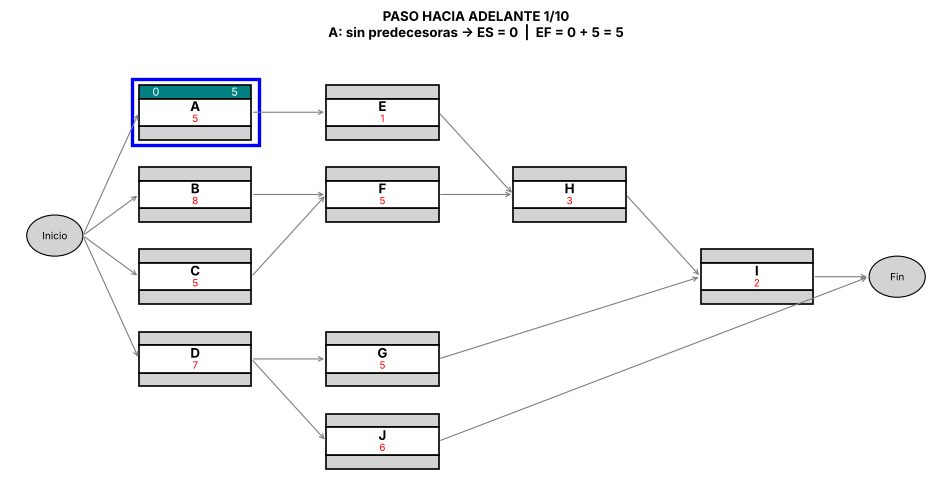

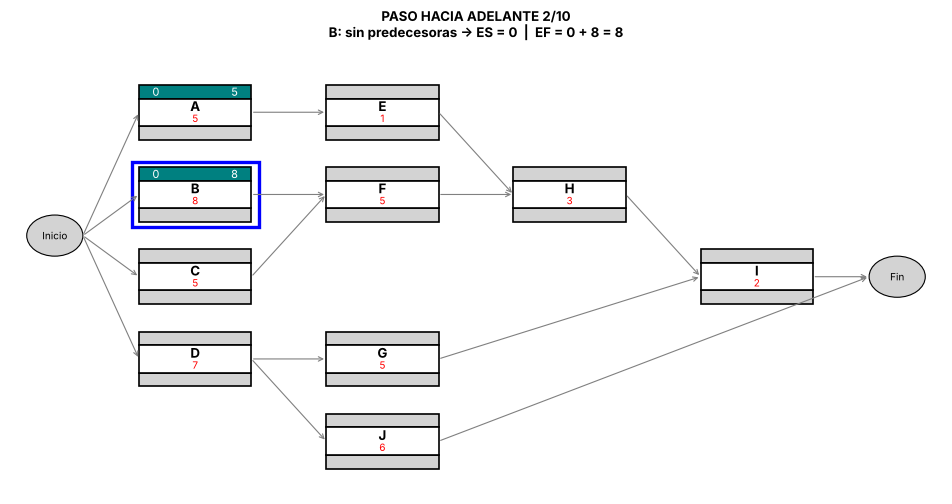

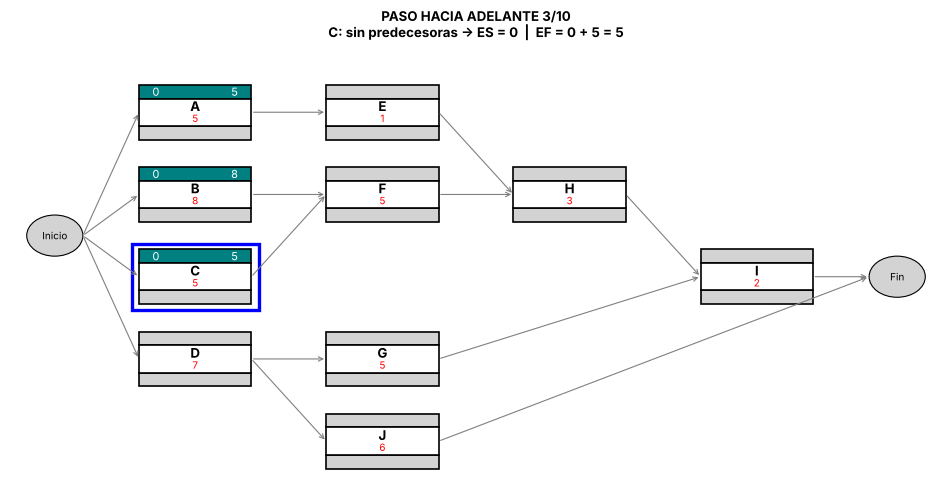

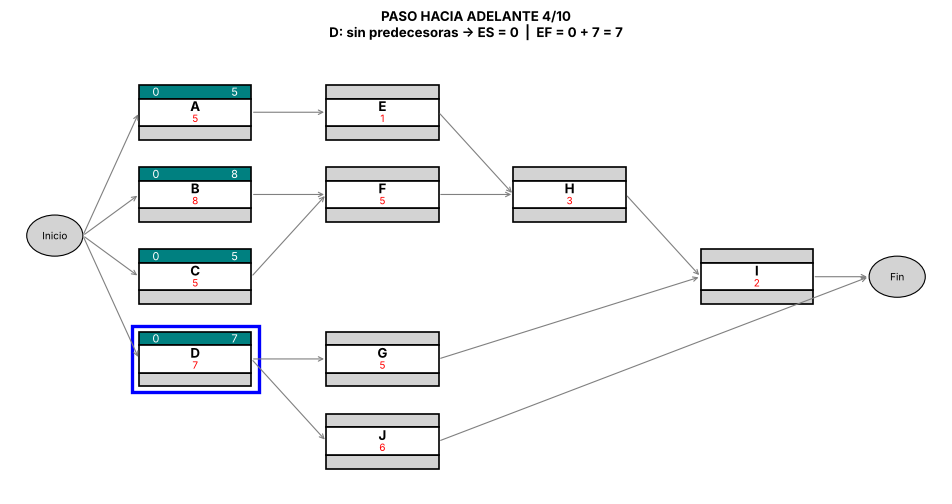

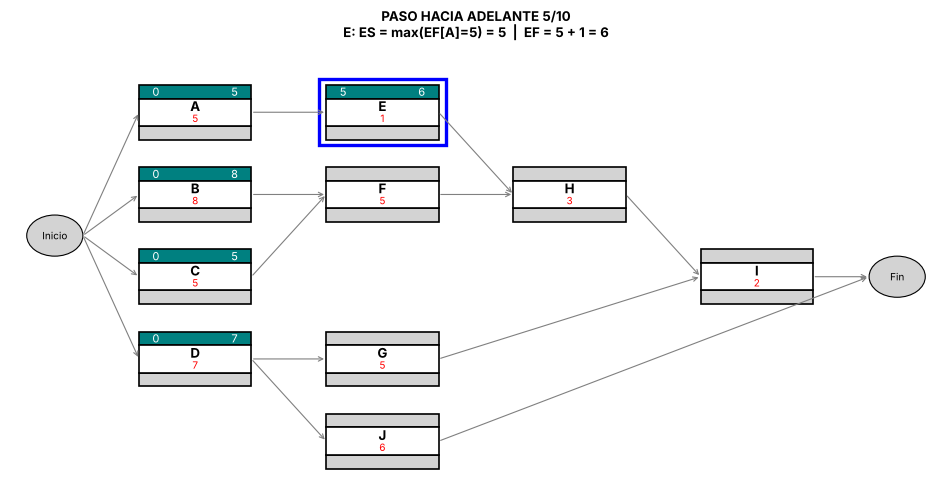

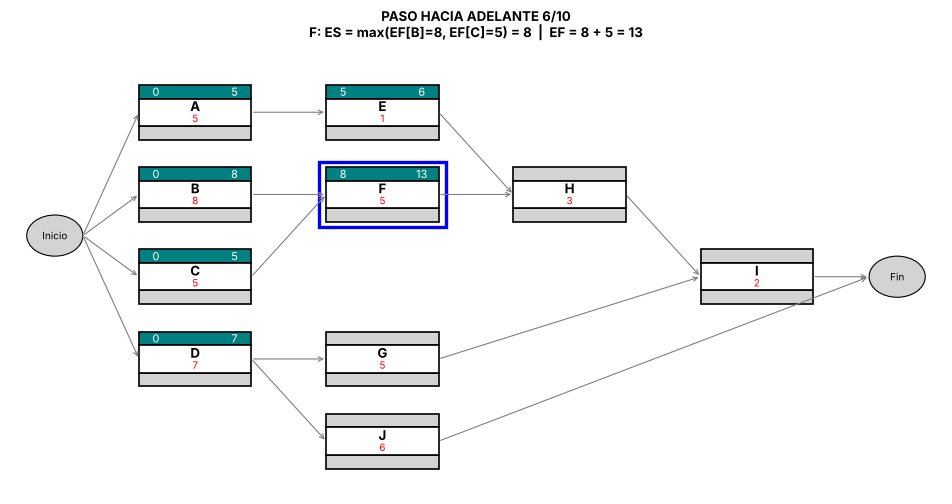

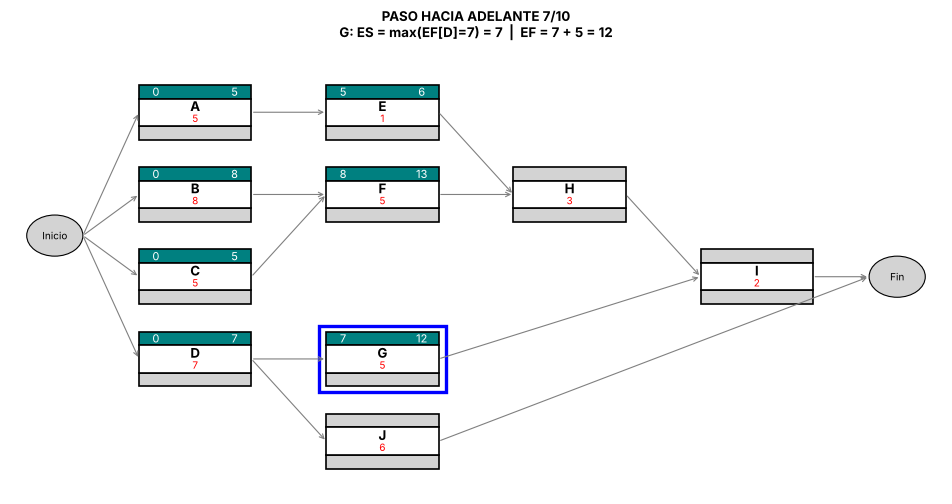

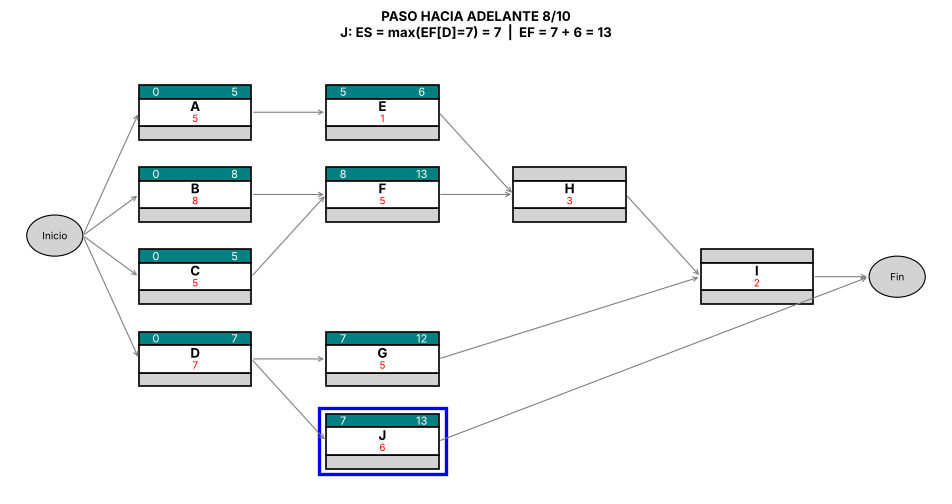

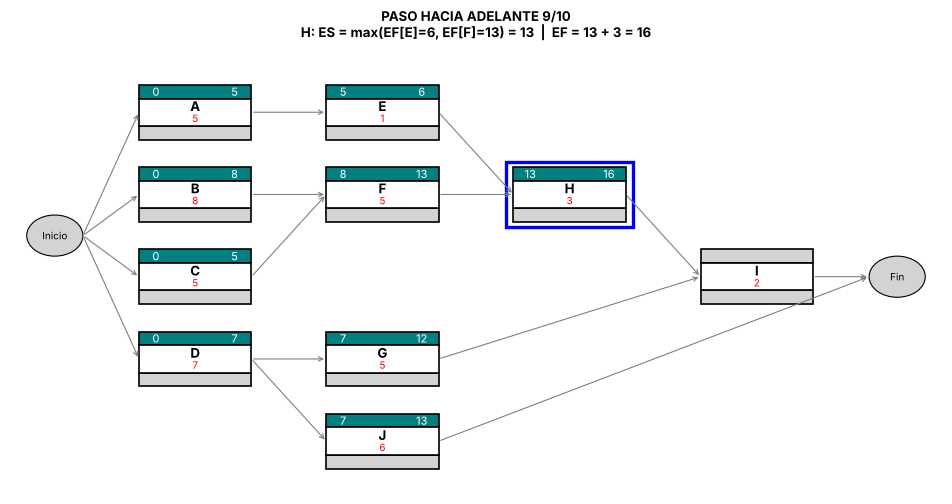

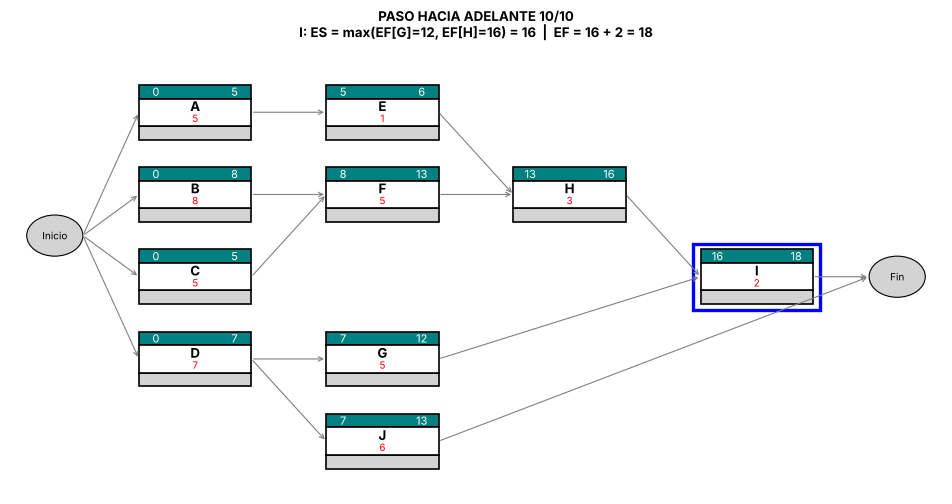

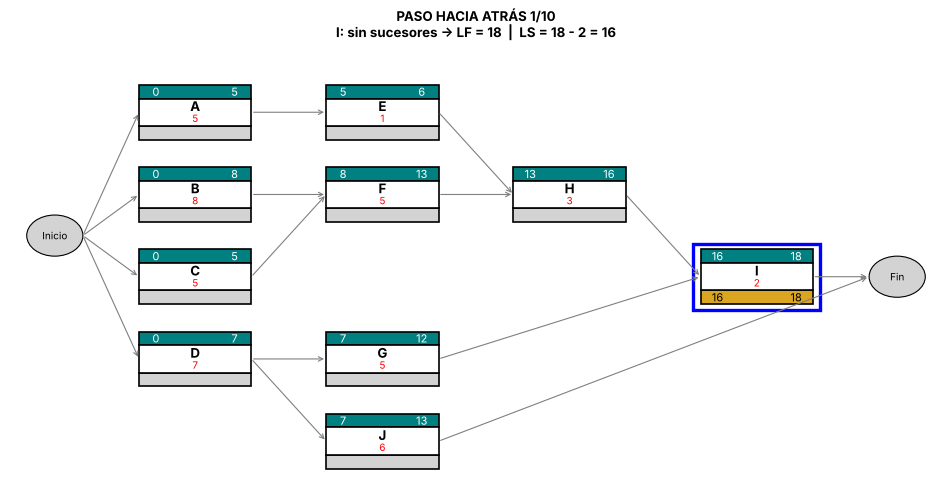

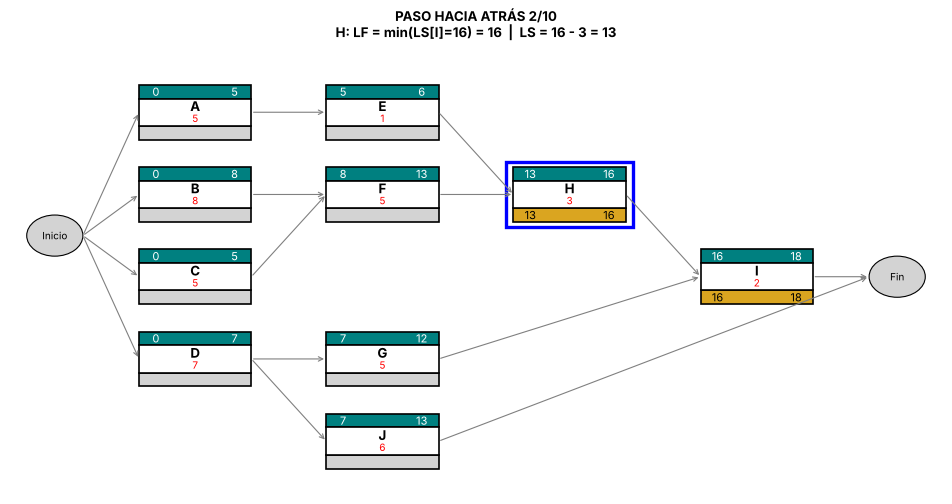

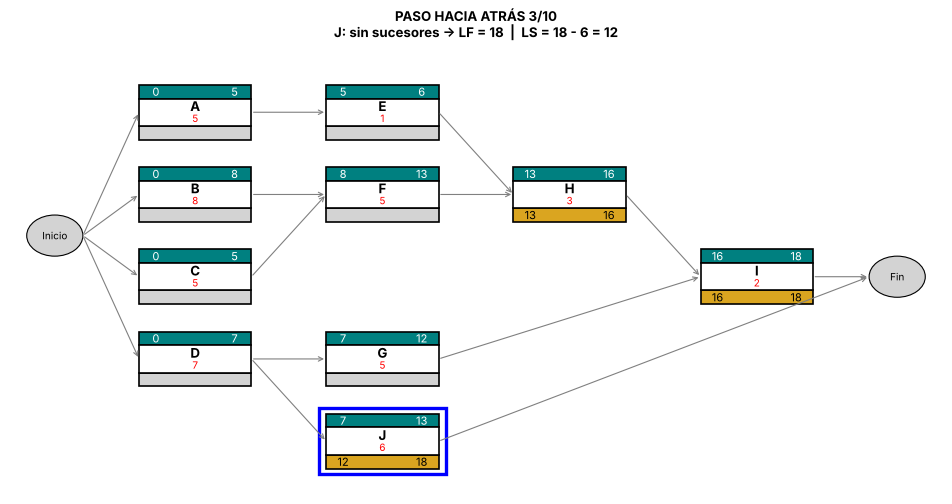

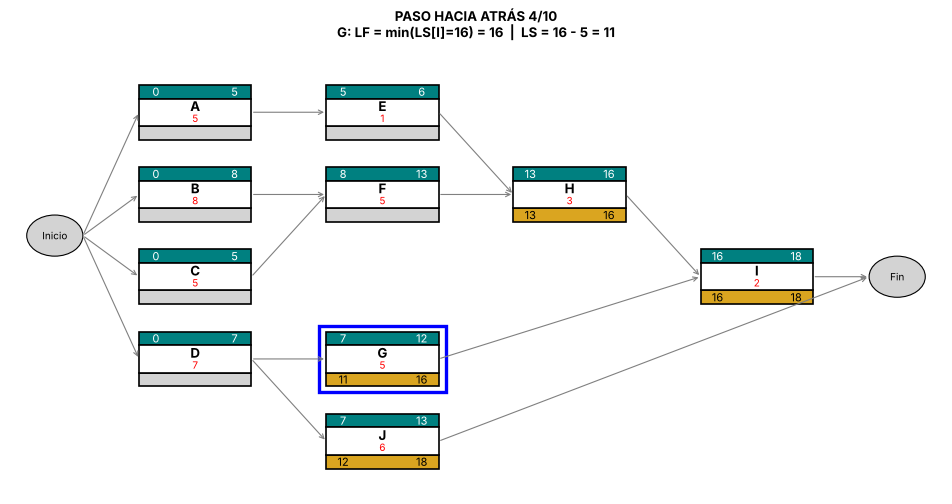

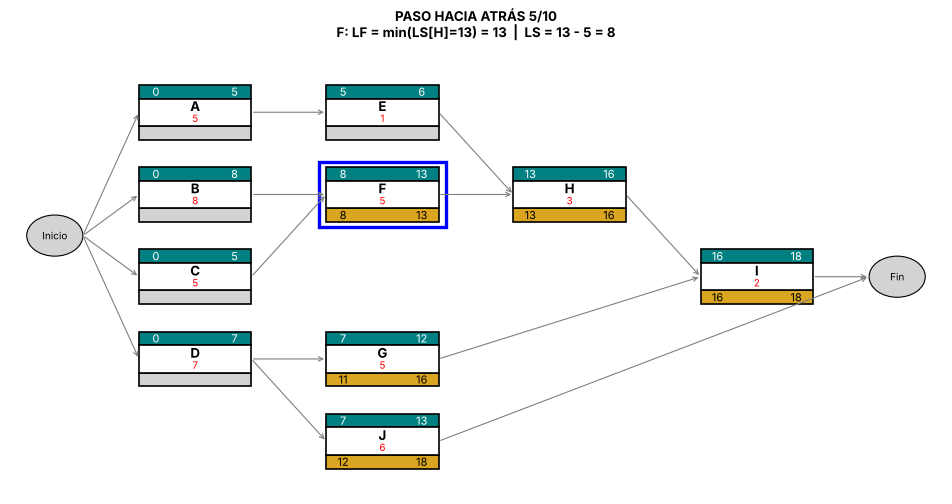

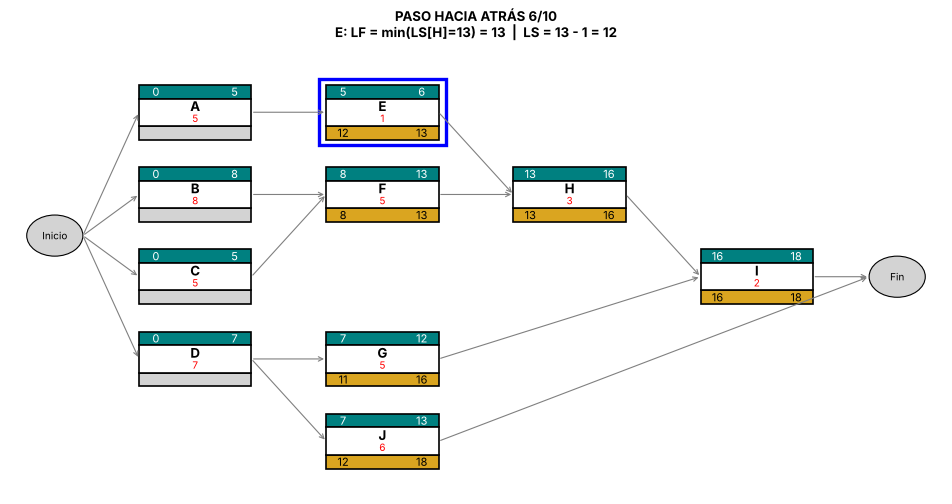

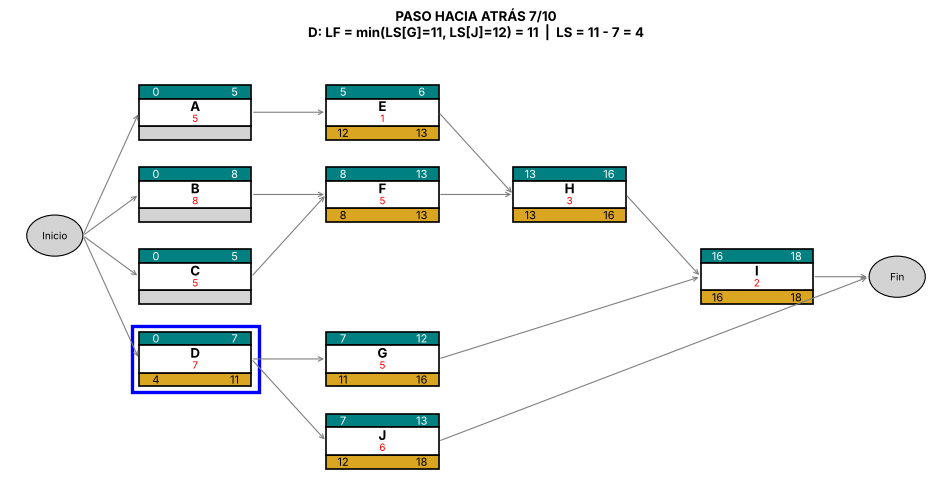

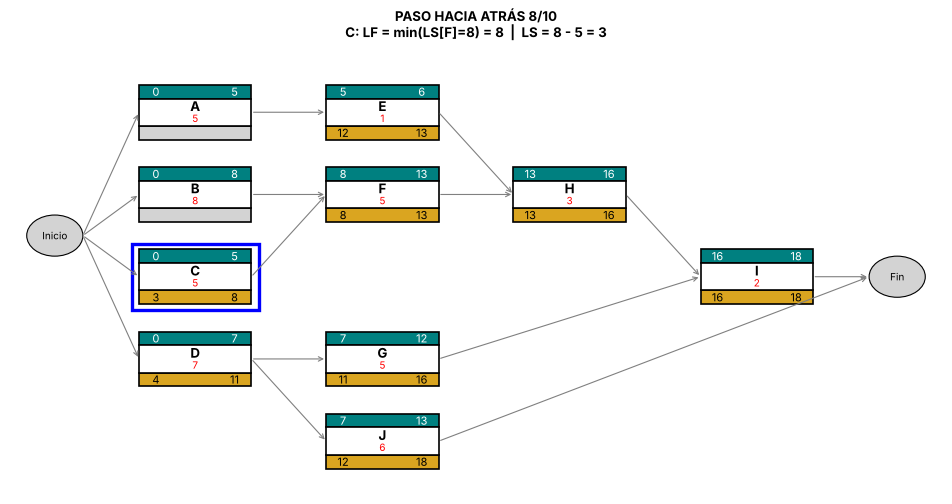

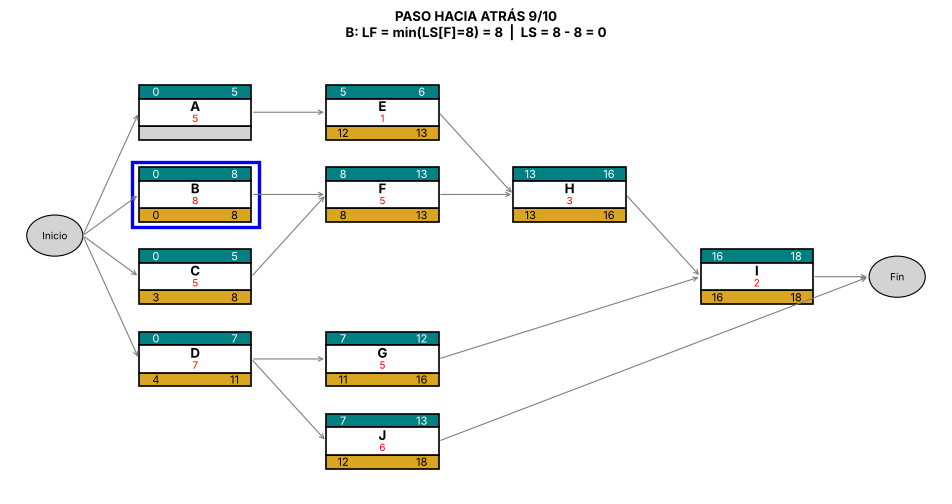

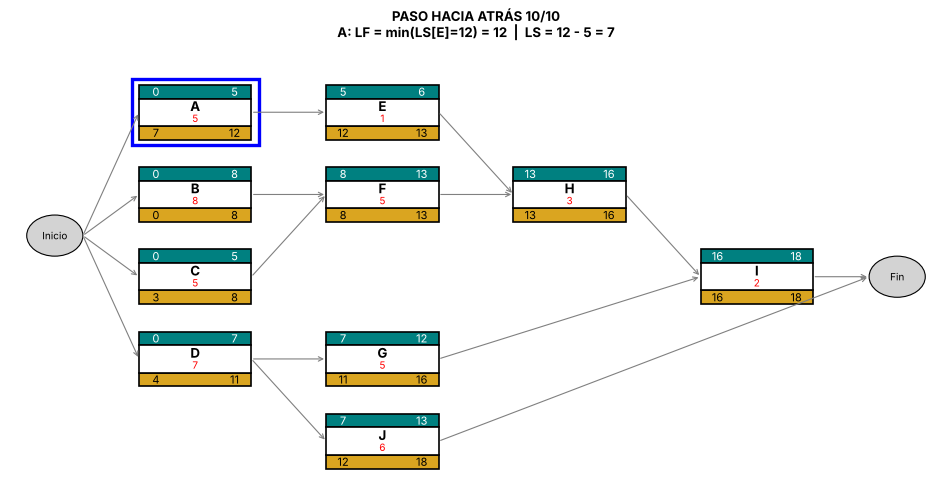

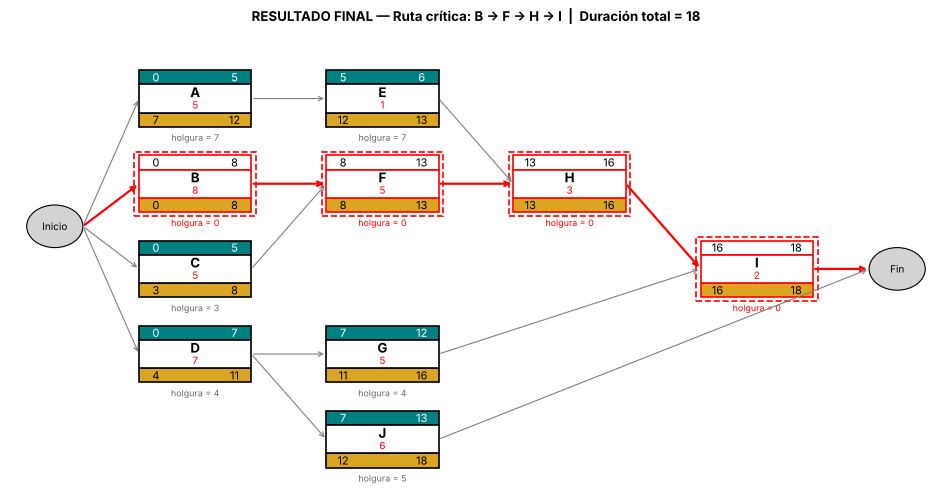

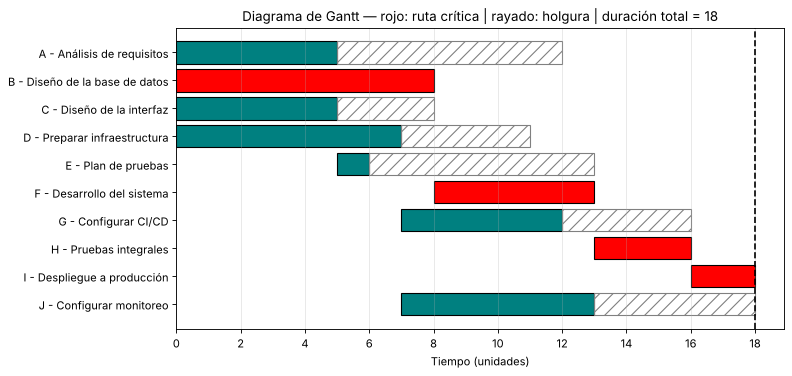

In [10]:
sucesores = sucesores_de(actividades)
orden = orden_topologico(actividades)

con_sucesor = {p for d in actividades.values() for p in d['pred']}
flechas = [('Inicio', n) for n, d in actividades.items() if not d['pred']]
flechas += [(p, n) for n, d in actividades.items() for p in d['pred']]
flechas += [(n, 'Fin') for n in actividades if n not in con_sucesor]

centro_nodo = {'Inicio': (0.5, 1.6), 'Fin': (9.5, 1.0)}

def dibujar_caja(ax, x, y, nombre, es, ef, ls, lf, dur, critica=False, activa=False):
    w, h = 1.2, 0.8
    txt = lambda v: '' if v is None else str(v)
    top_conocido = es is not None
    bot_conocido = ls is not None
    if critica:
        relleno_top, linea, texto_top = 'white', 'red', 'black'
    else:
        relleno_top = 'teal' if top_conocido else 'lightgray'
        linea, texto_top = 'black', ('white' if top_conocido else 'black')
    relleno_bot = 'goldenrod' if bot_conocido else 'lightgray'

    if activa:   # resalta la actividad que se calcula en este paso
        ax.add_patch(patches.Rectangle((x - w/2 - 0.08, y - h/2 - 0.08), w + 0.16, h + 0.16,
                                       linewidth=3, edgecolor='blue', facecolor='none'))
    # barra superior (ES | EF), franja central (nombre y duración) y barra inferior (LS | LF)
    ax.add_patch(patches.Rectangle((x - w/2, y + h/4), w, h/4, linewidth=1.5, edgecolor=linea, facecolor=relleno_top))
    ax.add_patch(patches.Rectangle((x - w/2, y - h/2), w, h/4, linewidth=1.5, edgecolor=linea, facecolor=relleno_bot))
    ax.add_patch(patches.Rectangle((x - w/2, y - h/4), w, h/2, linewidth=1.5, edgecolor=linea, facecolor='white'))
    ax.text(x - 0.42, y + 3*h/8, txt(es), ha='center', va='center', color=texto_top, fontsize=10)
    ax.text(x + 0.42, y + 3*h/8, txt(ef), ha='center', va='center', color=texto_top, fontsize=10)
    ax.text(x - 0.42, y - 3*h/8, txt(ls), ha='center', va='center', fontsize=10)
    ax.text(x + 0.42, y - 3*h/8, txt(lf), ha='center', va='center', fontsize=10)
    ax.text(x, y + h/9, nombre, ha='center', va='center', fontweight='bold', fontsize=12)
    ax.text(x, y - h/9, str(dur), ha='center', va='center', color='red', fontsize=9)
    if critica:
        ax.add_patch(patches.Rectangle((x - w/2 - 0.05, y - h/2 - 0.05), w + 0.1, h + 0.1,
                                       linewidth=1.5, edgecolor='red', facecolor='none', linestyle='--'))

def dibujar_nodo(ax, x, y, texto):
    ax.add_patch(patches.Circle((x, y), radius=0.3, edgecolor='black', facecolor='lightgray'))
    ax.text(x, y, texto, ha='center', va='center', fontsize=9)

def dibujar_diagrama(estado, titulo, activa=None, criticas=(), holguras=None):
    fig, ax = plt.subplots(figsize=(12, 6.4))
    ax.set_xlim(0, 10); ax.set_ylim(-2.2, 4.4); ax.axis('off')
    dibujar_nodo(ax, *centro_nodo['Inicio'], 'Inicio')
    dibujar_nodo(ax, *centro_nodo['Fin'], 'Fin')
    for n in actividades:
        x, y = posiciones_caja[n]
        e = estado.get(n, {})
        dibujar_caja(ax, x, y, n, e.get('ES'), e.get('EF'), e.get('LS'), e.get('LF'),
                     actividades[n]['dur'], n in criticas, n == activa)
        if holguras is not None:
            ax.text(x, y - 0.55, f"holgura = {holguras[n]}", ha='center', va='center', fontsize=8,
                    color='red' if holguras[n] == 0 else 'dimgray')
    for origen, destino in flechas:
        x1, y1 = centro_nodo.get(origen, posiciones_caja.get(origen))
        x2, y2 = centro_nodo.get(destino, posiciones_caja.get(destino))
        x1 += 0.3 if origen == 'Inicio' else 0.6
        x2 -= 0.3 if destino == 'Fin' else 0.6
        if origen == 'Inicio':
            es_crit = destino in criticas
        elif destino == 'Fin':
            es_crit = origen in criticas
        else:
            es_crit = origen in criticas and destino in criticas
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle="->", color='red' if es_crit else 'gray', lw=2 if es_crit else 1))
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

# ---------- PASO HACIA ADELANTE ----------
estado = {}
for k, n in enumerate(orden, 1):
    estado[n] = {'ES': ES[n], 'EF': EF[n]}
    dibujar_diagrama(estado, f"PASO HACIA ADELANTE {k}/{len(orden)}\n" + formula_adelante(n, actividades, ES, EF), activa=n)

# ---------- PASO HACIA ATRÁS ----------
for k, n in enumerate(reversed(orden), 1):
    estado[n] = {**estado[n], 'LS': LS[n], 'LF': LF[n]}
    dibujar_diagrama(estado, f"PASO HACIA ATRÁS {k}/{len(orden)}\n" + formula_atras(n, actividades, sucesores, LS, LF, duracion_total), activa=n)

# ---------- RESULTADO FINAL: holguras y ruta crítica ----------
estado_final = {n: {'ES': ES[n], 'EF': EF[n], 'LS': LS[n], 'LF': LF[n]} for n in actividades}
dibujar_diagrama(estado_final,
                 f"RESULTADO FINAL — Ruta crítica: {' → '.join(ruta_critica)}  |  Duración total = {duracion_total}",
                 criticas=ruta_critica, holguras=holgura)

# ---------- Diagrama de Gantt (barra = duración, rayado = holgura disponible) ----------
fig, ax = plt.subplots(figsize=(10, 4.8))
nombres = sorted(actividades)
for i, n in enumerate(reversed(nombres)):
    ax.barh(i, actividades[n]['dur'], left=ES[n], color='red' if n in ruta_critica else 'teal', edgecolor='black')
    if holgura[n] > 0:
        ax.barh(i, holgura[n], left=EF[n], color='none', edgecolor='gray', hatch='//')
ax.set_yticks(range(len(nombres)))
ax.set_yticklabels([f"{n} - {descripcion[n]}" for n in reversed(nombres)])
ax.set_xlabel('Tiempo (unidades)')
ax.axvline(duracion_total, color='black', linestyle='--')
ax.set_xticks(range(0, duracion_total + 1, 2))
ax.set_title(f"Diagrama de Gantt — rojo: ruta crítica | rayado: holgura | duración total = {duracion_total}")
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 8. Análisis final
- **Duración total del proyecto**: 18 unidades.
- **Ruta crítica**: B → F → H → I (holgura 0) → no pueden retrasarse.
- Las actividades A y E (holgura 7), D y G (holgura 4), C (holgura 3) y J (holgura 5) pueden demorarse hasta ese tiempo sin afectar la fecha final.
- Las gráficas paso a paso muestran cómo el paso hacia adelante fija el tiempo más temprano de cada actividad y el paso hacia atrás el más tardío; donde coinciden, la holgura es 0.
- Cualquier retraso en la ruta crítica retrasa el proyecto completo.
- **Aplicación TI**: planificación de sprints, despliegues, migraciones.

# Práctica 3: Ruta más corta con Dijkstra

## 1. Descripción del problema
Red de 8 routers/ciudades. Se requiere la ruta más corta entre el nodo A y el nodo H
(menor latencia acumulada).

## 2. Formulación matemática
- Grafo G = (V, E) con pesos w ≥ 0.
- Encontrar el camino P de A a H que minimice ∑ w(e) para e ∈ P.
- Algoritmo de Dijkstra con cola de prioridad: complejidad O((V+E) log V).

**¿Por qué funciona?** Siempre se procesa el nodo no visitado con menor distancia conocida; como no hay pesos
negativos, esa distancia ya no puede mejorar y queda fijada (optimalidad).

### 3. Importación de bibliotecas

In [11]:
import heapq
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 80

### 4. Definición de datos

In [12]:
aristas_dij = [
    ('A','B', 4), ('A','C', 2), ('B','C', 5), ('B','D', 10),
    ('C','E', 3), ('E','D', 4), ('D','F', 11), ('E','F', 8),
    ('E','G', 7), ('F','H', 2), ('G','H', 6), ('D','H', 15)
]

G_dij = nx.Graph()
G_dij.add_weighted_edges_from(aristas_dij)

# Posiciones fijas (layout manual) para comparar todas las figuras
pos_d = {'A': (0, 2), 'B': (2, 3.2), 'C': (2, 0.6), 'E': (4.2, 0.6),
         'D': (4.6, 3.2), 'F': (6.6, 1.4), 'G': (6.2, -0.6), 'H': (8.8, 1.2)}

print(f"Nodos: {G_dij.number_of_nodes()}  |  Aristas: {G_dij.number_of_edges()}")
print(f"Pesos no negativos: {all(w >= 0 for _, _, w in aristas_dij)}")
print()
print(pd.DataFrame(aristas_dij, columns=['Origen','Destino','Latencia']).to_string(index=False))

Nodos: 8  |  Aristas: 12
Pesos no negativos: True

Origen Destino  Latencia
     A       B         4
     A       C         2
     B       C         5
     B       D        10
     C       E         3
     E       D         4
     D       F        11
     E       F         8
     E       G         7
     F       H         2
     G       H         6
     D       H        15


### 5. Desarrollo del algoritmo

In [13]:
def dijkstra_manual(grafo, inicio, verbose=False):
    dist = {n: float('inf') for n in grafo.nodes()}   # distancia mínima conocida
    prev = {n: None for n in grafo.nodes()}           # predecesor para reconstruir el camino
    dist[inicio] = 0
    heap = [(0, inicio)]                              # cola de prioridad (distancia, nodo)
    visitados = set()
    historial = []                                    # foto del estado en cada paso (para graficar)

    if verbose:
        print(f"--- Inicio Dijkstra desde {inicio} ---")
    while heap:
        d, u = heapq.heappop(heap)
        if u in visitados:
            continue                                  # entrada vieja con peor distancia
        visitados.add(u)
        cambios = []
        if verbose:
            print(f"Procesando {u} (d={d})")
        for v, datos in grafo[u].items():
            nd = d + datos['weight']                  # relajación de la arista (u, v)
            if nd < dist[v]:
                dist[v] = nd
                prev[v] = u
                heapq.heappush(heap, (nd, v))
                cambios.append((v, nd))
                if verbose:
                    print(f"   Actualiza {v}: dist={nd} (prev={u})")
        historial.append({'paso': len(historial) + 1, 'nodo': u, 'dist_u': d, 'cambios': cambios,
                          'dist': dict(dist), 'prev': dict(prev), 'visitados': set(visitados)})
    return dist, prev, historial

def ruta(prev, destino):
    camino = []
    while destino:
        camino.append(destino)
        destino = prev[destino]
    return list(reversed(camino))

### 6. Ejecución paso a paso

In [14]:
dist, prev, historial_d = dijkstra_manual(G_dij, 'A', verbose=True)

camino = ruta(prev, 'H')
print()
print("Distancias mínimas desde A:", dist)
print(f"Ruta más corta A → H: {' → '.join(camino)}")
print(f"Distancia total: {dist['H']}")

# Verificación contra NetworkX
camino_nx = nx.dijkstra_path(G_dij, 'A', 'H', weight='weight')
costo_nx = nx.dijkstra_path_length(G_dij, 'A', 'H', weight='weight')
print(f"NetworkX: {' → '.join(camino_nx)} (costo {costo_nx}) | coincide: {camino_nx == camino and costo_nx == dist['H']}")
assert camino_nx == camino and costo_nx == dist['H']

--- Inicio Dijkstra desde A ---
Procesando A (d=0)
   Actualiza B: dist=4 (prev=A)
   Actualiza C: dist=2 (prev=A)
Procesando C (d=2)
   Actualiza E: dist=5 (prev=C)
Procesando B (d=4)
   Actualiza D: dist=14 (prev=B)
Procesando E (d=5)
   Actualiza D: dist=9 (prev=E)
   Actualiza F: dist=13 (prev=E)
   Actualiza G: dist=12 (prev=E)
Procesando D (d=9)
   Actualiza H: dist=24 (prev=D)
Procesando G (d=12)
   Actualiza H: dist=18 (prev=G)
Procesando F (d=13)
   Actualiza H: dist=15 (prev=F)
Procesando H (d=15)

Distancias mínimas desde A: {'A': 0, 'B': 4, 'C': 2, 'D': 9, 'E': 5, 'F': 13, 'G': 12, 'H': 15}
Ruta más corta A → H: A → C → E → F → H
Distancia total: 15
NetworkX: A → C → E → F → H (costo 15) | coincide: True


### 7. Visualización de resultados — gráfica paso a paso
Se dibuja **una figura por cada nodo que Dijkstra fija**. Cada nodo muestra su distancia actual
(∞ si aún no se alcanza). Colores: 🟠 nodo que se fija ahora, 🟢 nodos ya fijados, 🟡 nodos con distancia tentativa,
⚪ nodos sin alcanzar. Aristas: azul = mejor predecesor conocido, rojo = mejora hecha en este paso.

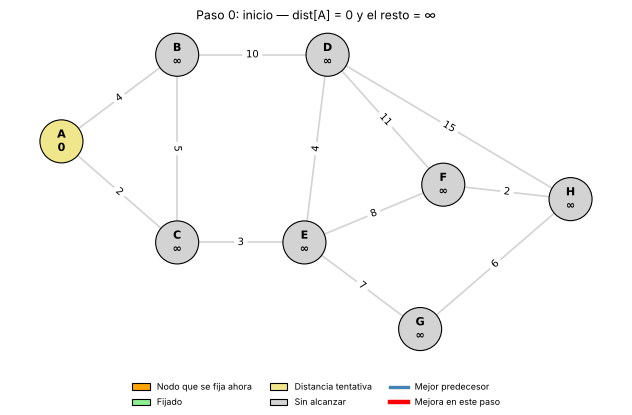

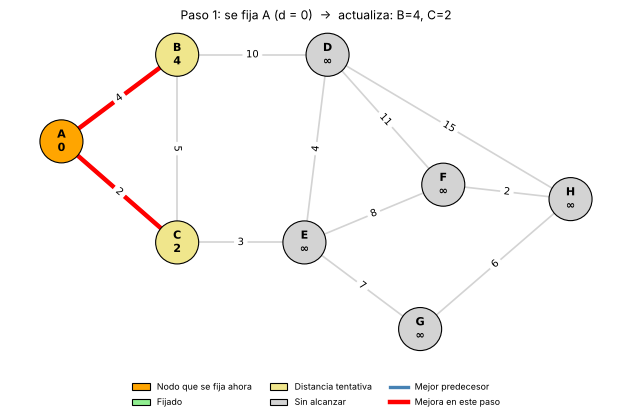

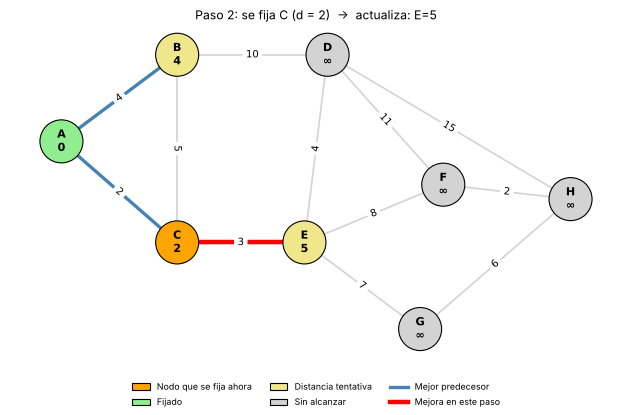

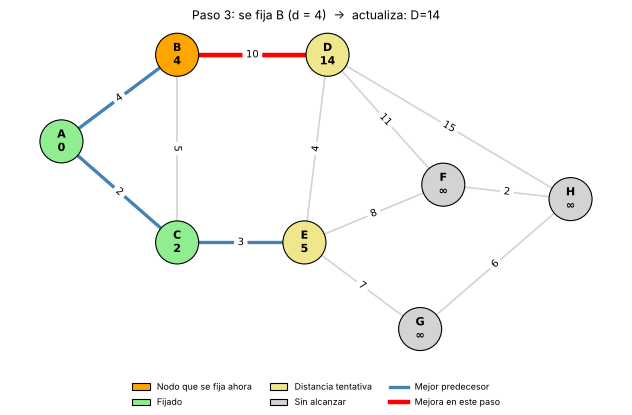

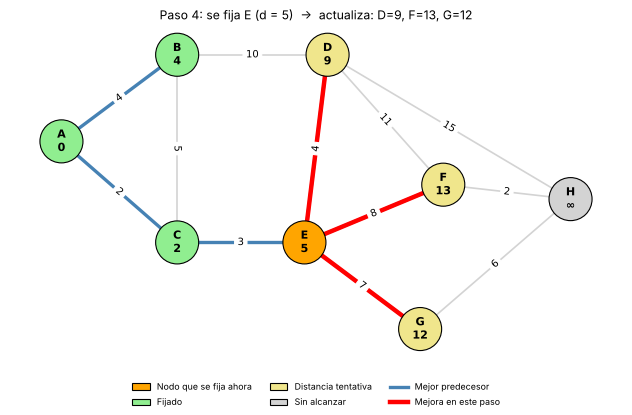

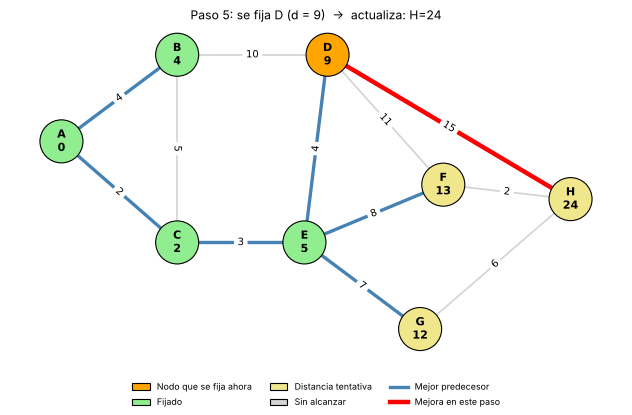

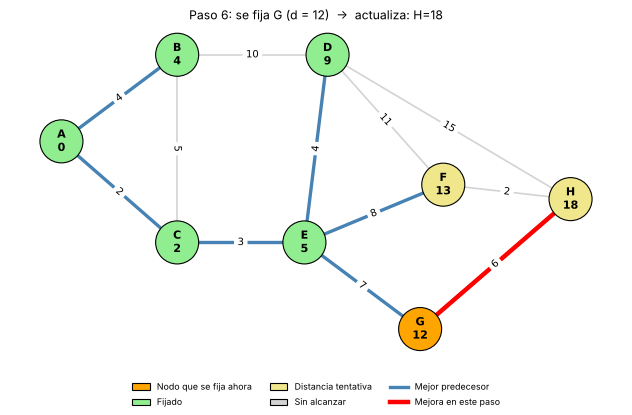

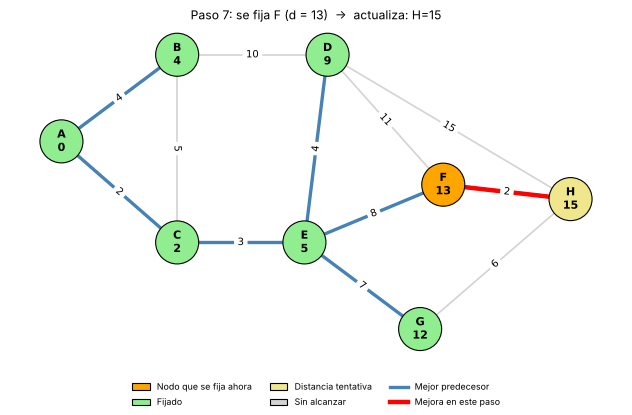

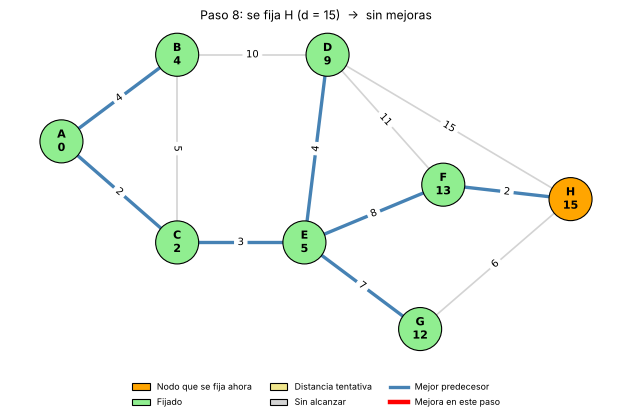

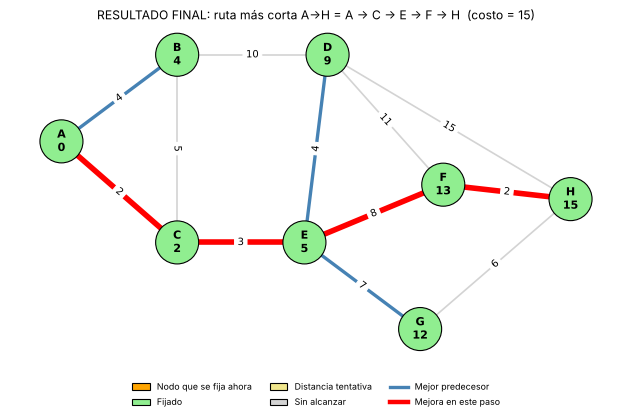

In [15]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

lbl = nx.get_edge_attributes(G_dij, 'weight')
leyenda_d = [Patch(facecolor='orange', edgecolor='black', label='Nodo que se fija ahora'),
             Patch(facecolor='lightgreen', edgecolor='black', label='Fijado'),
             Patch(facecolor='khaki', edgecolor='black', label='Distancia tentativa'),
             Patch(facecolor='lightgray', edgecolor='black', label='Sin alcanzar'),
             Line2D([0], [0], color='steelblue', lw=3, label='Mejor predecesor'),
             Line2D([0], [0], color='red', lw=4, label='Mejora en este paso')]

def dibujar_paso_dijkstra(titulo, estado, nodo_actual=None, cambios=(), camino_final=None):
    fig, ax = plt.subplots(figsize=(8, 5.2))
    colores = []
    for n in G_dij.nodes():
        if n == nodo_actual:                       colores.append('orange')
        elif n in estado['visitados']:             colores.append('lightgreen')
        elif estado['dist'][n] < float('inf'):     colores.append('khaki')
        else:                                      colores.append('lightgray')
    aristas_prev = [(p, n) for n, p in estado['prev'].items() if p is not None]
    nuevas = [(nodo_actual, v) for v, _ in cambios]

    nx.draw_networkx_edges(G_dij, pos_d, ax=ax, edge_color='lightgray', width=1.5)
    nx.draw_networkx_edges(G_dij, pos_d, ax=ax, edgelist=aristas_prev, edge_color='steelblue', width=3)
    if nuevas:
        nx.draw_networkx_edges(G_dij, pos_d, ax=ax, edgelist=nuevas, edge_color='red', width=4)
    if camino_final:
        nx.draw_networkx_edges(G_dij, pos_d, ax=ax, edgelist=list(zip(camino_final[:-1], camino_final[1:])),
                               edge_color='red', width=5)
    nx.draw_networkx_nodes(G_dij, pos_d, ax=ax, node_color=colores, node_size=1500, edgecolors='black')
    etiquetas = {n: f"{n}\n{'∞' if estado['dist'][n] == float('inf') else estado['dist'][n]}" for n in G_dij.nodes()}
    nx.draw_networkx_labels(G_dij, pos_d, labels=etiquetas, ax=ax, font_size=10, font_weight='bold')
    nx.draw_networkx_edge_labels(G_dij, pos_d, edge_labels=lbl, ax=ax, font_size=9)
    ax.set_title(titulo, fontsize=11)
    ax.axis('off')
    fig.legend(handles=leyenda_d, loc='lower center', ncol=3, fontsize=8, frameon=False)
    plt.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()

# Paso 0: estado inicial
inicial = {'dist': {n: (0 if n == 'A' else float('inf')) for n in G_dij.nodes()},
           'prev': {n: None for n in G_dij.nodes()}, 'visitados': set()}
dibujar_paso_dijkstra("Paso 0: inicio — dist[A] = 0 y el resto = ∞", inicial)

# Un paso por cada nodo fijado
for h in historial_d:
    if h['cambios']:
        texto = "actualiza: " + ", ".join(f"{v}={nd}" for v, nd in h['cambios'])
    else:
        texto = "sin mejoras"
    dibujar_paso_dijkstra(f"Paso {h['paso']}: se fija {h['nodo']} (d = {h['dist_u']})  →  {texto}",
                          h, nodo_actual=h['nodo'], cambios=h['cambios'])

# Resultado final
final = historial_d[-1]
dibujar_paso_dijkstra(f"RESULTADO FINAL: ruta más corta A→H = {' → '.join(camino)}  (costo = {dist['H']})",
                      final, camino_final=camino)

### 8. Análisis final
- La **ruta más corta** A→H es A → C → E → F → H, mostrada en rojo, con costo total de 15 (2 + 3 + 8 + 2).
- H se actualizó tres veces (24, 18 y 15): Dijkstra no se queda con la primera ruta encontrada sino con la mejor.
- Las gráficas paso a paso muestran cómo la zona de nodos fijados (verde) crece desde A en orden creciente de distancia.
- Dijkstra garantiza optimalidad porque **todos los pesos son no negativos**; el resultado coincide con `nx.dijkstra_path`.
- **Aplicación TI**: enrutamiento de paquetes, GPS, latencia mínima en redes SDN.

# Práctica 4: Programación Lineal

## 1. Descripción del problema
Una empresa de TI fabrica **2 tipos de servidores**: tipo A y tipo B.
- Servidor A: requiere 4 h de ensamblaje y 2 h de pruebas → ganancia $300.
- Servidor B: requiere 3 h de ensamblaje y 4 h de pruebas → ganancia $250.
- Disponibilidad semanal: 240 h de ensamblaje y 200 h de pruebas.
- Demanda máxima de A: 40 unidades.

Se requiere decidir cuántos servidores de cada tipo fabricar para maximizar la ganancia semanal.

## 2. Formulación matemática
Variables: x_A, x_B = servidores tipo A y B por semana.

**Maximizar** Z = 300·x_A + 250·x_B

**Sujeto a:**
- 4·x_A + 3·x_B ≤ 240   (ensamblaje)
- 2·x_A + 4·x_B ≤ 200   (pruebas)
- x_A ≤ 40               (demanda)
- x_A, x_B ≥ 0

**¿Por qué PL?** La función objetivo y todas las restricciones son lineales y los recursos son limitados.
Por el teorema fundamental de la PL, la solución óptima siempre está en un **vértice** de la región factible.

### 3. Importación de bibliotecas

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.optimize import linprog

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 80

### 4. Definición de datos

In [17]:
c = [-300, -250]                    # linprog MINIMIZA, por eso maximizar Z = minimizar -Z
A_ub = [[4, 3],
        [2, 4],
        [1, 0]]
b_ub = [240, 200, 40]
bounds = [(0, None), (0, None)]     # x_A >= 0, x_B >= 0

nombres_restricciones = ['Ensamblaje', 'Pruebas', 'Demanda A']
print(pd.DataFrame({'Coef x_A': [r[0] for r in A_ub], 'Coef x_B': [r[1] for r in A_ub],
                    'Límite (≤)': b_ub}, index=nombres_restricciones).to_string())
print()
print("Función objetivo: Z = 300*x_A + 250*x_B  (linprog minimiza, por eso c = -Z)")

            Coef x_A  Coef x_B  Límite (≤)
Ensamblaje         4         3         240
Pruebas            2         4         200
Demanda A          1         0          40

Función objetivo: Z = 300*x_A + 250*x_B  (linprog minimiza, por eso c = -Z)


### 5. Desarrollo del algoritmo (enumeración de vértices + verificación con linprog)

In [18]:
def vertices_factibles(A_ub, b_ub, nombres, verbose=False):
    """Intersecta cada par de restricciones (como igualdades) y conserva los puntos factibles."""
    restricciones = [(a[0], a[1], b, nom) for a, b, nom in zip(A_ub, b_ub, nombres)]
    restricciones += [(-1, 0, 0, 'x_A >= 0'), (0, -1, 0, 'x_B >= 0')]
    vertices = []
    for r1, r2 in combinations(restricciones, 2):
        M = np.array([[r1[0], r1[1]], [r2[0], r2[1]]], dtype=float)
        if abs(np.linalg.det(M)) < 1e-12:             # rectas paralelas: no se cortan
            if verbose:
                print(f"  {r1[3]:>10} ∩ {r2[3]:<10} -> paralelas (sin intersección)")
            continue
        p = np.round(np.linalg.solve(M, [r1[2], r2[2]]), 9) + 0.0
        factible = all(r[0]*p[0] + r[1]*p[1] <= r[2] + 1e-9 for r in restricciones)
        if verbose:
            print(f"  {r1[3]:>10} ∩ {r2[3]:<10} -> ({p[0]:6.2f}, {p[1]:6.2f})  {'FACTIBLE' if factible else 'no factible'}")
        if factible and not any(np.allclose(p, q) for q in vertices):
            vertices.append(p)
    return vertices

def ganancia(p):
    return 300 * p[0] + 250 * p[1]

### 6. Ejecución paso a paso

In [19]:
print("Intersecciones de cada par de restricciones:")
vertices = vertices_factibles(A_ub, b_ub, nombres_restricciones, verbose=True)
vertices = sorted(vertices, key=lambda q: (q[0], q[1]))

print()
print("Vértices de la región factible y su ganancia:")
for p in vertices:
    print(f"  (x_A={p[0]:6.2f}, x_B={p[1]:6.2f})  ->  Z = {ganancia(p):9.2f}")

mejor = max(vertices, key=ganancia)
print(f"\nMejor vértice: x_A={mejor[0]:.2f}, x_B={mejor[1]:.2f}, Z={ganancia(mejor):.2f}")

res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method='highs')
print()
print("Estado:", res.message)
print(f"x_A = {res.x[0]:.2f} servidores tipo A")
print(f"x_B = {res.x[1]:.2f} servidores tipo B")
print(f"Ganancia máxima Z = {-res.fun:.2f} $")
assert np.allclose(res.x, mejor) and abs(-res.fun - ganancia(mejor)) < 1e-6

print()
print("Uso de recursos en el óptimo:")
for nombre, a, b in zip(nombres_restricciones, A_ub, b_ub):
    uso = a[0]*res.x[0] + a[1]*res.x[1]
    print(f"  {nombre}: {uso:.2f} de {b}  (holgura {b - uso:.2f})")

Intersecciones de cada par de restricciones:
  Ensamblaje ∩ Pruebas    -> ( 36.00,  32.00)  FACTIBLE
  Ensamblaje ∩ Demanda A  -> ( 40.00,  26.67)  FACTIBLE
  Ensamblaje ∩ x_A >= 0   -> (  0.00,  80.00)  no factible
  Ensamblaje ∩ x_B >= 0   -> ( 60.00,   0.00)  no factible
     Pruebas ∩ Demanda A  -> ( 40.00,  30.00)  no factible
     Pruebas ∩ x_A >= 0   -> (  0.00,  50.00)  FACTIBLE
     Pruebas ∩ x_B >= 0   -> (100.00,   0.00)  no factible
   Demanda A ∩ x_A >= 0   -> paralelas (sin intersección)
   Demanda A ∩ x_B >= 0   -> ( 40.00,   0.00)  FACTIBLE
    x_A >= 0 ∩ x_B >= 0   -> (  0.00,   0.00)  FACTIBLE

Vértices de la región factible y su ganancia:
  (x_A=  0.00, x_B=  0.00)  ->  Z =      0.00
  (x_A=  0.00, x_B= 50.00)  ->  Z =  12500.00
  (x_A= 36.00, x_B= 32.00)  ->  Z =  18800.00
  (x_A= 40.00, x_B=  0.00)  ->  Z =  12000.00
  (x_A= 40.00, x_B= 26.67)  ->  Z =  18666.67

Mejor vértice: x_A=36.00, x_B=32.00, Z=18800.00

Estado: Optimization terminated successfully. (HiGHS S

### 7. Visualización de resultados — gráfica paso a paso
Se construye la solución gráfica **poco a poco**:
1. Se traza cada restricción por separado (3 figuras) con su semiplano permitido.
2. Se sombrea la **región factible** (intersección) y se marcan sus vértices.
3. Se **evalúa Z en cada vértice**, uno por figura, recordando el mejor encontrado hasta ese momento.
4. Se muestran las **rectas de isoganancia** que se desplazan hasta tocar el último punto de la región.
5. Se presenta el **óptimo final** y el uso de recursos.

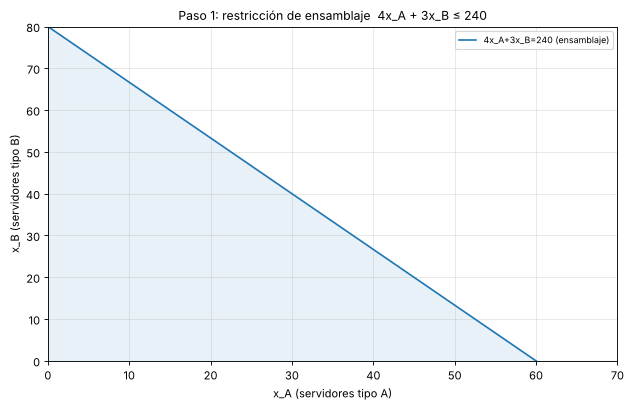

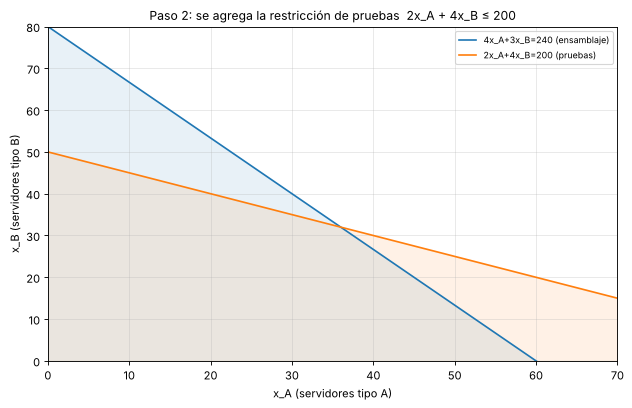

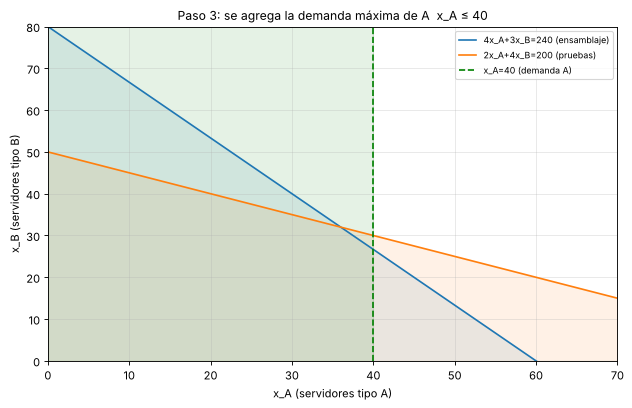

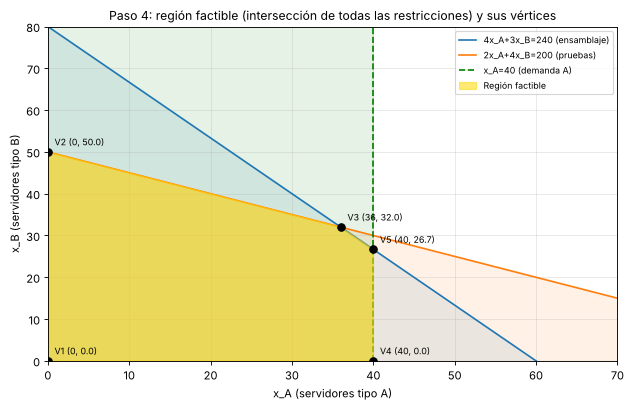

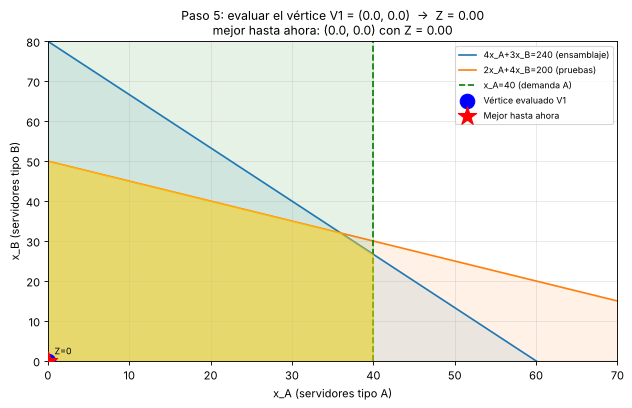

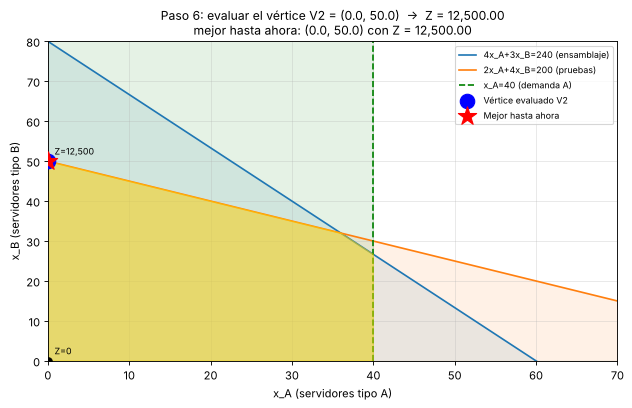

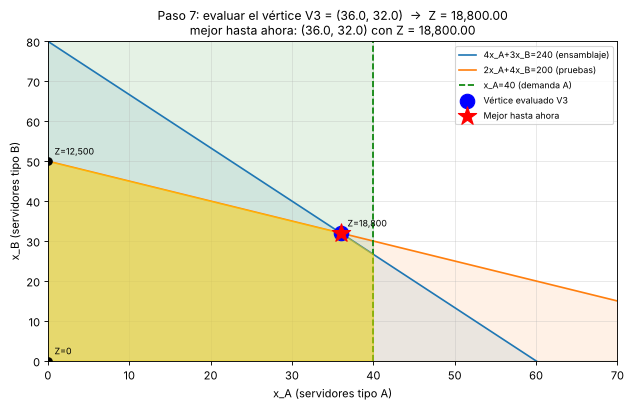

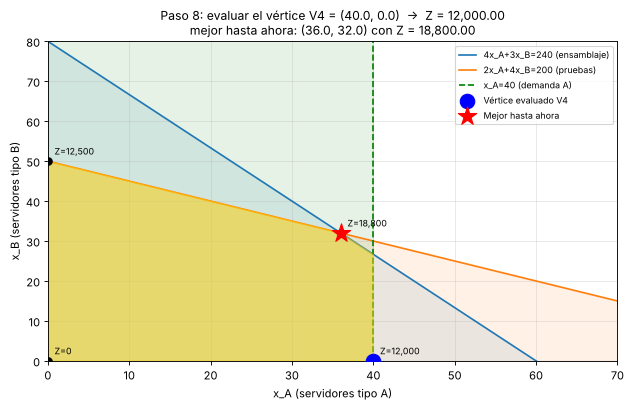

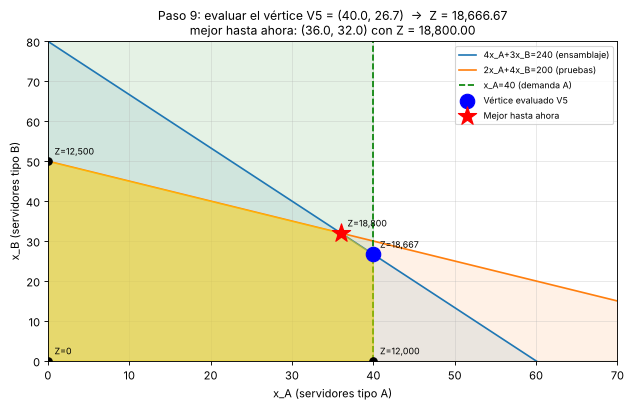

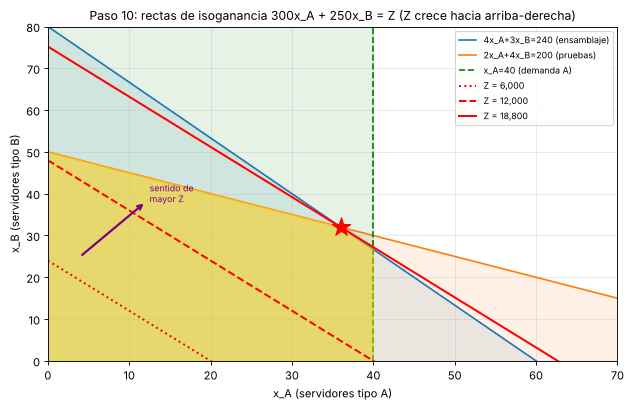

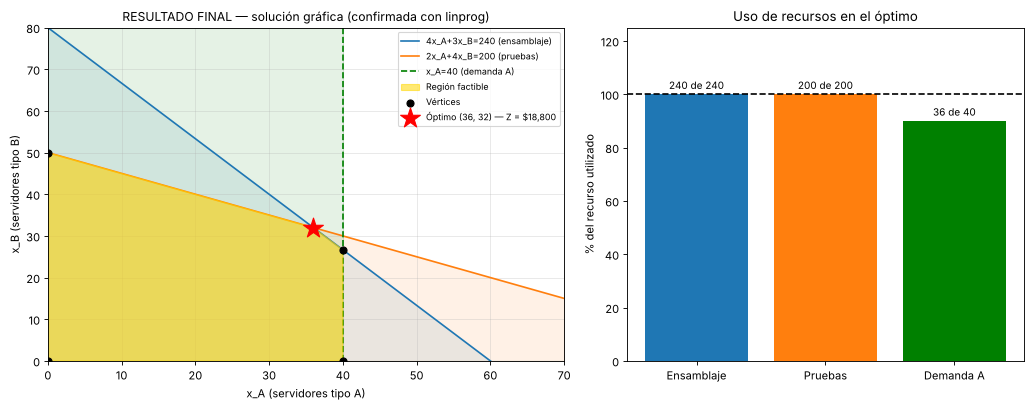

In [20]:
x = np.linspace(0, 70, 400)
y1 = (240 - 4*x) / 3
y2 = (200 - 2*x) / 4

def lienzo(titulo, figsize=(8, 5.2)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 70); ax.set_ylim(0, 80)
    ax.set_xlabel('x_A (servidores tipo A)'); ax.set_ylabel('x_B (servidores tipo B)')
    ax.grid(alpha=0.3); ax.set_title(titulo, fontsize=11)
    return fig, ax

def trazar_restricciones(ax, hasta):
    if hasta >= 1:
        ax.plot(x, y1, color='tab:blue', label='4x_A+3x_B=240 (ensamblaje)')
        ax.fill_between(x, 0, np.clip(y1, 0, 80), alpha=0.10, color='tab:blue')
    if hasta >= 2:
        ax.plot(x, y2, color='tab:orange', label='2x_A+4x_B=200 (pruebas)')
        ax.fill_between(x, 0, np.clip(y2, 0, 80), alpha=0.10, color='tab:orange')
    if hasta >= 3:
        ax.axvline(40, color='green', linestyle='--', label='x_A=40 (demanda A)')
        ax.axvspan(0, 40, alpha=0.10, color='green')

def poligono_factible(vs):
    cx, cy = np.mean([v[0] for v in vs]), np.mean([v[1] for v in vs])
    return sorted(vs, key=lambda v: np.arctan2(v[1] - cy, v[0] - cx))

# ---- Pasos 1-3: una restricción por figura ----
titulos = ["Paso 1: restricción de ensamblaje  4x_A + 3x_B ≤ 240",
           "Paso 2: se agrega la restricción de pruebas  2x_A + 4x_B ≤ 200",
           "Paso 3: se agrega la demanda máxima de A  x_A ≤ 40"]
for k in (1, 2, 3):
    fig, ax = lienzo(titulos[k - 1])
    trazar_restricciones(ax, k)
    ax.legend(loc='upper right', fontsize=8)
    plt.tight_layout(); plt.show()

# ---- Paso 4: región factible y vértices ----
poli = poligono_factible(vertices)
fig, ax = lienzo("Paso 4: región factible (intersección de todas las restricciones) y sus vértices")
trazar_restricciones(ax, 3)
ax.fill(*zip(*poli), color='gold', alpha=0.55, label='Región factible', zorder=2)
for i, p in enumerate(vertices, 1):
    ax.scatter(*p, color='black', s=45, zorder=4)
    ax.annotate(f"V{i} ({p[0]:.0f}, {p[1]:.1f})", p, textcoords='offset points', xytext=(6, 6), fontsize=8)
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

# ---- Pasos 5 en adelante: evaluar Z en cada vértice ----
mejor_hasta_ahora = None
for i, p in enumerate(vertices, 1):
    Z = ganancia(p)
    if mejor_hasta_ahora is None or Z > ganancia(mejor_hasta_ahora):
        mejor_hasta_ahora = p
    fig, ax = lienzo(f"Paso {4 + i}: evaluar el vértice V{i} = ({p[0]:.1f}, {p[1]:.1f})  →  Z = {Z:,.2f}\n"
                     f"mejor hasta ahora: ({mejor_hasta_ahora[0]:.1f}, {mejor_hasta_ahora[1]:.1f}) con Z = {ganancia(mejor_hasta_ahora):,.2f}")
    trazar_restricciones(ax, 3)
    ax.fill(*zip(*poli), color='gold', alpha=0.45, zorder=2)
    for j, q in enumerate(vertices[:i], 1):
        ax.scatter(*q, color='black', s=45, zorder=4)
        ax.annotate(f"Z={ganancia(q):,.0f}", q, textcoords='offset points', xytext=(6, 6), fontsize=8)
    ax.scatter(*p, color='blue', s=170, zorder=5, label=f'Vértice evaluado V{i}')
    ax.scatter(*mejor_hasta_ahora, color='red', marker='*', s=300, zorder=6, label='Mejor hasta ahora')
    ax.legend(loc='upper right', fontsize=8)
    plt.tight_layout(); plt.show()

# ---- Rectas de isoganancia ----
fig, ax = lienzo("Paso 10: rectas de isoganancia 300x_A + 250x_B = Z (Z crece hacia arriba-derecha)")
trazar_restricciones(ax, 3)
ax.fill(*zip(*poli), color='gold', alpha=0.45, zorder=2)
for Z, estilo in [(6000, ':'), (12000, '--'), (ganancia(mejor), '-')]:
    ax.plot(x, (Z - 300*x) / 250, color='red', linestyle=estilo, linewidth=1.8, label=f'Z = {Z:,.0f}')
ax.annotate('', xy=(12, 38), xytext=(4, 25), arrowprops=dict(arrowstyle='->', color='purple', lw=2))
ax.text(12.5, 38, 'sentido de\nmayor Z', color='purple', fontsize=8)
ax.scatter(*mejor, color='red', marker='*', s=300, zorder=6)
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

# ---- Resultado final ----
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.3, 1]})
ax.set_xlim(0, 70); ax.set_ylim(0, 80); ax.grid(alpha=0.3)
ax.set_xlabel('x_A (servidores tipo A)'); ax.set_ylabel('x_B (servidores tipo B)')
trazar_restricciones(ax, 3)
ax.fill(*zip(*poli), color='gold', alpha=0.55, label='Región factible', zorder=2)
ax.scatter([v[0] for v in vertices], [v[1] for v in vertices], color='black', s=40, zorder=4, label='Vértices')
ax.scatter([res.x[0]], [res.x[1]], color='red', marker='*', s=350, zorder=5,
           label=f"Óptimo ({res.x[0]:.0f}, {res.x[1]:.0f}) — Z = ${-res.fun:,.0f}")
ax.set_title("RESULTADO FINAL — solución gráfica (confirmada con linprog)", fontsize=11)
ax.legend(loc='upper right', fontsize=8)

usos = [a[0]*res.x[0] + a[1]*res.x[1] for a in A_ub]
porc = [100 * u / b for u, b in zip(usos, b_ub)]
barras = ax2.bar(nombres_restricciones, porc, color=['tab:blue', 'tab:orange', 'green'])
ax2.axhline(100, color='black', linestyle='--')
for barra, u, b in zip(barras, usos, b_ub):
    ax2.text(barra.get_x() + barra.get_width()/2, barra.get_height() + 2, f"{u:.0f} de {b}", ha='center', fontsize=9)
ax2.set_ylim(0, 125); ax2.set_ylabel('% del recurso utilizado')
ax2.set_title("Uso de recursos en el óptimo")
plt.tight_layout(); plt.show()

### 8. Análisis final
- La solución óptima es producir **x_A = 36** y **x_B = 32** servidores por semana.
- Ganancia máxima semanal = **$18,800**.
- Ambas restricciones de ensamblaje y pruebas están **activas** (se usan las 240 h y las 200 h): son el recurso limitante.
- La demanda de A no es limitante (36 < 40, holgura 4).
- El óptimo se encuentra en un vértice de la región factible, como confirma la comparación de ganancias de todos los vértices y las gráficas paso a paso (el mayor Z, $18,800, se alcanza en V3 = (36, 32)).
- **Aplicación TI**: planificación de capacidad de manufactura, asignación de recursos cloud, presupuestos de proyectos.

## Conclusiones individuales
- **[Akis Aram Seba Toto]**: Aprendí a implementar Kruskal mostrando el porqué de aceptar/rechazar cada arista, reforzando la comprensión del MST.
- **[Cristian Saul Soto Vique]**: El cálculo manual de ES/EF/LS/LF me permitió entender el valor de la holgura en la gestión de proyectos.
- **[Luis Alberto Rodriguez Rodriguez]**: Dijkstra con cola de prioridad mostró claramente la diferencia entre exploración ciega y dirigida.

## Conclusión del equipo
Las cuatro prácticas permitieron vincular los modelos clásicos de Investigación de Operaciones con problemas reales de Tecnologías de la Información. El uso de Python + NetworkX + SciPy evidencia que es posible construir herramientas de apoyo a la decisión de forma rápida y reproducible, documentando cada paso con Markdown y **graficando cada paso de los algoritmos** para garantizar trazabilidad.